# Práctica final IA: YouTube Trending Videos

A partir de los datos de los vídeos en tendencias diarias de YouTube de 10 países, se resuelven varios problemas de negocio con técnicas de machine learning: predecir la categoría del vídeo, predecir el número de likes, encontrar grupos de vídeos con técnicas de clusterización y recomendar vídeos parecidos.

## Índice

1. Preprocesamiento
2. Análisis exploratorio
3. Predicción de la categoría del vídeo
4. Reto opcional: comentarios o ratings desactivados
5. Predicción del número de likes
6. Clusterización
7. Recomendador
8. Conclusiones finales

## 1. Preprocesamiento

In [723]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

Actualizamos la categoria de nuestro fichero csv en base a los datos que tenemos en el fichero JSON.

In [724]:
def actualizacion_categoria_pais(ruta_csv, ruta_json, nombre_pais):

    """Función que actualiza la category_id del Csv reemplazando por el valor string asignado en el fichero json y añade columna con el pais."""
    
    dfjson = pd.read_json(ruta_json)#en vez de leer linea por linea, empaqueta todo el json
    dfjson_aplanado = pd.json_normalize(dfjson['items'])
    dfjson_items = pd.DataFrame({'json_id': dfjson_aplanado['id'].astype(str),'category': dfjson_aplanado['snippet.title']})
    
    dfcsv = pd.read_csv(ruta_csv, encoding='utf-8', encoding_errors='replace')
    dfcsv['category_id'] = dfcsv['category_id'].astype(str)
    
    df_final = pd.merge(dfcsv, dfjson_items, left_on='category_id', right_on='json_id', how='left')
    
    df_final = df_final.drop(columns=['json_id', 'category_id'])

    df_final['pais'] = nombre_pais#creamos la columna pais 
                
    return df_final

In [725]:
paises = {"CA":"Canadá","DE":"Alemania","FR":"Francia","GB":"Gran Bretaña","IN":"India","JP":"Japón","KR":"Corea","MX":"Mexico","RU":"Rusia","US":"USA"}

In [726]:
dataframe_por_pais = (actualizacion_categoria_pais(f"{c}videos.csv", f"{c}_category_id.json", nombre) for c, nombre in paises.items())

Unificamos todos los dataframes

In [727]:
dataframe_final = pd.concat(dataframe_por_pais, ignore_index=True)

Confirmamos que en nuestro dataframe final hay registros de todos los paises.

In [728]:
dataframe_final.pais.value_counts()

pais
USA             40949
Canadá          40881
Alemania        40840
Rusia           40739
Francia         40724
Mexico          40451
Gran Bretaña    38916
India           37352
Corea           34567
Japón           20523
Name: count, dtype: int64

### Descripción de las variables

- **video_id:** Identificador único del vídeo en YouTube.
- **trending_date:** Fecha en la que el vídeo apareció en la lista de tendencias (formato año.día.mes).
- **title:** El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales).
- **channel_title:** El nombre original del canal de YouTube que subió el video.
- **category_id:** El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión.
- **publish_time:** Fecha y hora en la que se publicó el vídeo.
- **tags:** Las palabras clave asociadas al video.
- **views:** La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.
- **likes:** La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.
- **dislikes:** La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.
- **comment_count:** El número de comentarios totales escritos por los usuarios en ese día específico.
- **thumbnail_link:** Enlace a la imagen en miniatura del vídeo.
- **comments_disabled:** Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.
- **ratings_disabled:** Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.
- **video_error_or_removed:** Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.
- **description:** El texto explicativo original largo que el creador colocó en la caja de descripción del video.
- **pais:** El país donde se obtuvo el dato.

In [729]:
dataframe_final.shape

(375942, 17)

Procedemos a quitar los duplicados.

In [730]:
dataframe_final.drop_duplicates(inplace=True)

In [731]:
dataframe_final.shape

(363372, 17)

Se eliminan alrededor de 12000 duplicados

Estos son los items que tendremos que predecir:

1. Predecir la categoría del vídeo
2. Predecir el número de likes
3. Encontrar grupos en los vídeos mediante diversas técnicas de clusterización
4. Crear un recomendador

Las columnas video_id, description y thumbnail_link  no tiene ningún tipo de información que nos pueda ayudar. Las eliminamos.

In [732]:
dataframe_final.drop(["video_id", "thumbnail_link", "description"], axis=1, inplace=True)

In [733]:
dataframe_final.shape

(363372, 14)

In [734]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 363372 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           363372 non-null  object
 1   title                   363372 non-null  object
 2   channel_title           363372 non-null  object
 3   publish_time            363372 non-null  object
 4   tags                    363372 non-null  object
 5   views                   363372 non-null  int64 
 6   likes                   363372 non-null  int64 
 7   dislikes                363372 non-null  int64 
 8   comment_count           363372 non-null  int64 
 9   comments_disabled       363372 non-null  bool  
 10  ratings_disabled        363372 non-null  bool  
 11  video_error_or_removed  363372 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    363372 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vemos en category que hay algún nulo. Procedemos a eliminarlos

In [735]:
dataframe_final.dropna(inplace=True)

In [736]:
dataframe_final.shape

(360662, 14)

In [737]:
dataframe_final.info()#Confirmamos que se han quitado todos los nulos.

<class 'pandas.core.frame.DataFrame'>
Index: 360662 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           360662 non-null  object
 1   title                   360662 non-null  object
 2   channel_title           360662 non-null  object
 3   publish_time            360662 non-null  object
 4   tags                    360662 non-null  object
 5   views                   360662 non-null  int64 
 6   likes                   360662 non-null  int64 
 7   dislikes                360662 non-null  int64 
 8   comment_count           360662 non-null  int64 
 9   comments_disabled       360662 non-null  bool  
 10  ratings_disabled        360662 non-null  bool  
 11  video_error_or_removed  360662 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    360662 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vamos con title y channel title. Vemos que es un video de tendencias por lo que podria suceder que el mismo video fuera tendencia varios dias 
y por tantos los datos pudieran estar duplicados pero el drop_duplicates no haya funcionado porque las variables numéricas sean diferentes.

In [738]:
df_duplicados_ejemplos = dataframe_final[dataframe_final.duplicated(subset=["title", "channel_title"])]#keep false para valores unicos sin repetir duplicados
df_duplicados_ejemplos.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
200,17.15.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",2649977,193479,3496,17846,False,False,False,Comedy,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
216,17.15.11,STRANGER JOKES : Jokes de Papa avec les teens ...,"Le Jeu, C'est Sérieux",2017-11-13T15:48:57.000Z,"Stranger Jokes|""Jokes de Papa""|""Stranger Thing...",443131,27026,491,746,False,False,False,Comedy,Canadá
218,17.15.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,2017-11-13T17:13:01.000Z,SHANtell martin,2188675,88100,7150,24225,False,False,False,People & Blogs,Canadá
219,17.15.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",4326684,167696,6730,9265,False,False,False,Comedy,Canadá


Los registros que nos aparecen son registros que tienen más de un registro con el mismo nombre y canal. Veamos un ejemplo:

In [739]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
0,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,False,False,False,Music,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
498,17.16.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",22702386,869304,50018,123235,False,False,False,Music,Canadá
791,17.17.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania


Vemos que hay filas repetidas en las que como pasa aquí fue trending en varias ocasiones. Haremos filtrado y dejaremos un valor único por país teniendo en cuenta principalmente la variable views, ya que a priori a mas alta dicha variable mas likes, dislikes y comments debería haber ya que el formato youtube va acumulando cada dia dichos items. Tenemos en cuenta país ya que un mismo vídeo puede ser tendencia en dos o más países y de cara a nuestro modelo puede ser interesante.

Antes de quitar los duplicados pasamos trending_date a formato datetime y guardamos en primer_trending el primer día en que cada vídeo fue tendencia en cada país. Lo hacemos ahora porque, al quitar los duplicados, solo quedará la fila con más views y perderíamos esa fecha. La usaremos más adelante para calcular los días desde la publicación.

In [740]:
dataframe_final["trending_date"] = pd.to_datetime(dataframe_final["trending_date"], format="%y.%d.%m", errors="coerce").dt.floor('D')
primer_trending = dataframe_final.groupby(["channel_title", "title", "pais"])["trending_date"].transform("min")#primer día en tendencias de cada vídeo en cada país

In [741]:
dataframe_final.sort_values(by="views", ascending=False, inplace=True)
dataframe_final.drop_duplicates(subset=["channel_title", "title", "pais"],keep="first",inplace=True)

Una vez ordenados los datos y quitados los duplicados, confirmamos que efectivamente nos ha dejado un valor único por país y si habiendo varios registros iguales el que más views tiene (ver Canadá por ejemplo)

In [742]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
125227,2017-11-27,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",39235314,1044324,63815,137383,False,False,False,Music,Gran Bretaña
335988,2017-11-18,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",26448434,911883,53873,127481,False,False,False,Music,USA
791,2017-11-17,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania
81791,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem""|""Walk""|""On""|""Water""|""Aftermath/Shady/I...",17158579,787425,43420,125882,False,False,False,Music,Francia
219394,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787426,43420,125882,False,False,False,Music,Corea


In [743]:
dataframe_final.shape#Aligeramos el peso del dataframe.

(207525, 14)

In [744]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   trending_date           207525 non-null  datetime64[ns]
 1   title                   207525 non-null  object        
 2   channel_title           207525 non-null  object        
 3   publish_time            207525 non-null  object        
 4   tags                    207525 non-null  object        
 5   views                   207525 non-null  int64         
 6   likes                   207525 non-null  int64         
 7   dislikes                207525 non-null  int64         
 8   comment_count           207525 non-null  int64         
 9   comments_disabled       207525 non-null  bool          
 10  ratings_disabled        207525 non-null  bool          
 11  video_error_or_removed  207525 non-null  bool          
 12  category                207525

Procedemos a pasar publish_time a formato datetime y creamos la columna dias_desde_publicacion, que indica los días que pasaron desde que se publicó el vídeo hasta que fue tendencia por primera vez en cada país. Para ello usamos primer_trending, que calculamos antes de quitar los duplicados. Una vez calculada, eliminamos trending_date y publish_time, ya que no las vamos a usar más.

In [745]:
dataframe_final["publish_time"] = pd.to_datetime(dataframe_final["publish_time"], errors="coerce").dt.tz_localize(None).dt.floor('D')
dataframe_final["dias_desde_publicacion"] = (primer_trending.loc[dataframe_final.index] - dataframe_final["publish_time"]).dt.days.clip(lower=0)#con .loc nos quedamos solo con las filas que siguen en el dataframe tras quitar duplicados
dataframe_final.drop(["trending_date", "publish_time"], axis=1, inplace=True)#ya no las necesitamos: solo servían para calcular dias_desde_publicacion

In [746]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"Bad Bunny|""Amorfoda""|""Dura""|""Daddy Yankee""|""Oz...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"Te Bote|""Te Bote Remix""|""Flow La Movie""|""Ozuna...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"Bad|""Bunny""|""Bad Bunny""|""Video Oficial""|""Music...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"Ozuna|""Reggaeton""|""Odisea""|""Odisea The Album""|...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"Childish Gambino|""Rap""|""This Is America""|""mcDJ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Vamos a modificar los formatos de cada columna. Comenzaremos con title de tipo string. Procedemos a quitar los espacios 
y los posibles saltos de línea al introducir el nombre del title.

In [747]:
dataframe_final["title"] = (dataframe_final["title"].str.strip().str.split().str.join(" "))

Realizamos la misma transformación en channel_title:

In [748]:
dataframe_final["channel_title"] = (dataframe_final["channel_title"].str.strip().str.split().str.join(" "))

En el caso de tags, además de los espacios en blanco, quitamos las comillas, separamos por "|" y guardamos las etiquetas en una lista.

In [749]:
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split().str.join(" "))
dataframe_final["tags"] = dataframe_final["tags"].str.replace('"', '', regex=False)#regex=False: busca el texto tal cual, sin tratarlo como expresión regular
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split("|", regex=False))

In [750]:
def eliminar_etiquetas_vacias(lista_de_tags):
    """Filtra y elimina los elementos vacíos de la lista de etiquetas."""
    resultado = []
    for tag in lista_de_tags:
        if tag != '':
            resultado.append(tag)
    return resultado

# Aplicar la función al DataFrame
dataframe_final['tags'] = dataframe_final['tags'].apply(eliminar_etiquetas_vacias)

In [751]:
dataframe_final.head(5)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Limpio el dataset, lo guardamos en formato pickle y  pasamos al análisis exploratorio

In [752]:
dataframe_final.to_pickle("dataframe_final_limpio.pkl")

## 2. Análisis exploratorio

A continuación vamos a ver un poco los datos que tenemos después de procesar nuestro df. Para ello cargamos el dataset limpio que hemos guardado en formato pickle.

In [753]:
df = pd.read_pickle("dataframe_final_limpio.pkl")

In [754]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   title                   207525 non-null  object
 1   channel_title           207525 non-null  object
 2   tags                    207525 non-null  object
 3   views                   207525 non-null  int64 
 4   likes                   207525 non-null  int64 
 5   dislikes                207525 non-null  int64 
 6   comment_count           207525 non-null  int64 
 7   comments_disabled       207525 non-null  bool  
 8   ratings_disabled        207525 non-null  bool  
 9   video_error_or_removed  207525 non-null  bool  
 10  category                207525 non-null  object
 11  pais                    207525 non-null  object
 12  dias_desde_publicacion  207525 non-null  int64 
dtypes: bool(3), int64(5), object(5)
memory usage: 18.0+ MB


In [755]:
matriz_correlacion = df.corr(numeric_only=True)#sacamos la matriz de correlacion para ver relacion solo de las variables numéricas

In [756]:
print(matriz_correlacion)

                           views     likes  dislikes  comment_count  \
views                   1.000000  0.747095  0.442746       0.528759   
likes                   0.747095  1.000000  0.429676       0.803652   
dislikes                0.442746  0.429676  1.000000       0.637617   
comment_count           0.528759  0.803652  0.637617       1.000000   
comments_disabled      -0.006558 -0.022285 -0.006149      -0.022113   
ratings_disabled       -0.011216 -0.027856 -0.011366      -0.015297   
video_error_or_removed  0.006401  0.007036  0.002517       0.003513   
dias_desde_publicacion -0.002717 -0.005195 -0.002071      -0.004165   

                        comments_disabled  ratings_disabled  \
views                           -0.006558         -0.011216   
likes                           -0.022285         -0.027856   
dislikes                        -0.006149         -0.011366   
comment_count                   -0.022113         -0.015297   
comments_disabled                1.000000    

**Conclusiones:**

- **Likes y comment_count:** Si hay un like, suele haber un comentario de manera generalizada.
- **Views y likes:** A más visualizaciones más likes. Por lo tanto views, likes y comment_count suelen ir de la mano.
- **Dislikes con views, likes y comment_count:** Cuanto más se ve el video, más posibles dislikes puede provocar y por tanto, mas comentarios a modo de hate.

In [757]:
df.describe()

,views,likes,dislikes,comment_count,dias_desde_publicacion
count,2.075250e+05,2.075250e+05,2.075250e+05,2.075250e+05,207525.000000
mean,5.340433e+05,1.626300e+04,9.406069e+02,2.005660e+03,3.266994
std,3.279155e+06,8.822365e+04,1.250509e+04,1.409846e+04,62.288545
min,1.530000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2.581900e+04,3.750000e+02,2.300000e+01,6.000000e+01,1.000000
50%,9.312400e+04,1.732000e+03,9.400000e+01,2.710000e+02,1.000000
75%,3.247840e+05,7.470000e+03,3.720000e+02,1.041000e+03,1.000000
max,4.245389e+08,5.613827e+06,1.944971e+06,1.626501e+06,4215.000000


Podemos ver que los valores máximos y minimos distorsionan mucho con respecto a la media y si intentamos sacar outliers, vemos 
que hay en las variables views, likes, dislikes, comment_count y dias desde publicación. Esto es debido a la viralidad que se puede dar con cierto vídeo. Vamos a representar los outliers de views ya que como vimos anteriormente a partir de ella el resto de outliers que hemos visto también pueden aumentar dada su gran relación.

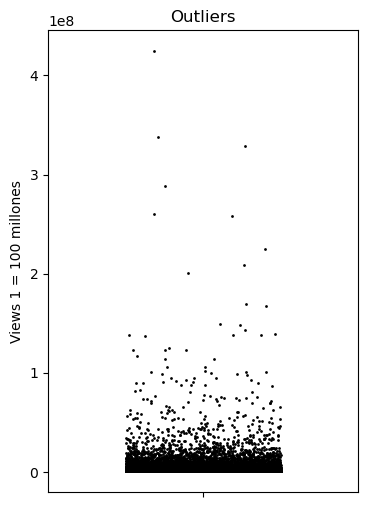

In [758]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1 #Rango intercuantílico
limite_outliers = Q3 + (1.5 * IQR)
df_outliers = df[df["views"] > limite_outliers]

plt.figure(figsize=(4, 6))
sns.stripplot(y=df_outliers["views"], color="black", jitter=0.25,size=2)

plt.title("Outliers")
plt.ylabel("Views 1 = 100 millones")
plt.show()

Vemos claramente los outliers y de cara al EDA los dejamos ya que según que planteamiento puede ser bueno quitarlos o no.

### Análisis univariado de variables categóricas

In [759]:
df.category.value_counts(normalize=True)

category
Entertainment            0.295540
People & Blogs           0.172495
News & Politics          0.114208
Sports                   0.075157
Music                    0.067139
Comedy                   0.063496
Film & Animation         0.052818
Howto & Style            0.051295
Gaming                   0.029828
Education                0.021183
Science & Technology     0.019718
Autos & Vehicles         0.016894
Pets & Animals           0.012191
Travel & Events          0.004563
Shows                    0.003315
Nonprofits & Activism    0.000072
Movies                   0.000072
Trailers                 0.000014
Name: proportion, dtype: float64

Vemos que más de la mitad de los videos son de la categoría Entertainment, People & Blogs y News & Politics.

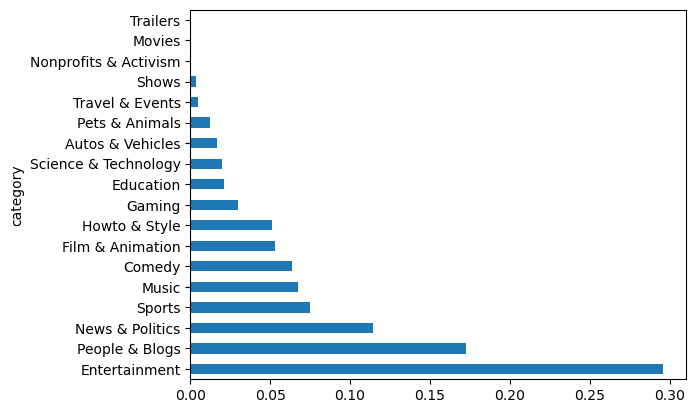

In [760]:
df.category.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que las categorías Trailers, Movies y Nonprofits & Activism tienen muy pocos registros

In [761]:
df.category.value_counts()[["Trailers", "Movies", "Nonprofits & Activism"]]

category
Trailers                  3
Movies                   15
Nonprofits & Activism    15
Name: count, dtype: int64

Procedemos a eliminarlas ya que, con tan pocos vídeos, quitan más de lo que aportan a los modelos.

In [762]:
df.drop(df[df["category"].isin(["Trailers", "Movies", "Nonprofits & Activism"])].index, inplace=True)

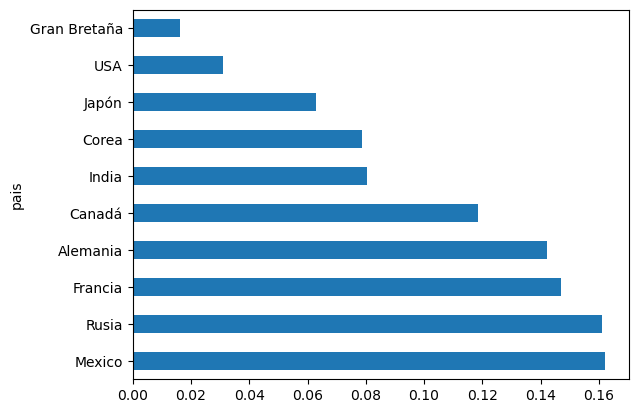

In [763]:
df.pais.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que lo datos se centran sobre todo en los paises Rusia, Mexico, Alemania, Francia y Canada

In [764]:
df['comments_disabled'].value_counts()

comments_disabled
False    202599
True       4893
Name: count, dtype: int64

In [765]:
df['ratings_disabled'].value_counts()

ratings_disabled
False    202860
True       4632
Name: count, dtype: int64

In [766]:
df['video_error_or_removed'].value_counts()

video_error_or_removed
False    207387
True        105
Name: count, dtype: int64

In [767]:
df.drop('video_error_or_removed', axis=1, inplace=True)

Vemos que no tiene ningún valor esta variable por lo que la eliminamos ahora aquí e insertamos la actualización el fichero preprocess.

In [768]:
df.sort_values(by='views', ascending=False).head(10)

,title,channel_title,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,category,pais,dias_desde_publicacion
150857,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,Music,Gran Bretaña,2
156905,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,Music,Gran Bretaña,3
147990,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,Music,Gran Bretaña,1
143607,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,Music,Gran Bretaña,2
160846,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,Music,Gran Bretaña,1
148381,Drake - God’s Plan,DrakeVEVO,"[Drake new music, Drake Gods Plan, Drake God’s...",258164991,4737873,117198,301756,False,False,Music,Gran Bretaña,5
373540,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,"[Childish Gambino, Rap, This Is America, mcDJ ...",225211923,5023450,343541,517232,False,False,Music,USA,2
158165,Ariana Grande - No Tears Left To Cry,ArianaGrandeVevo,"[Ariana, Grande, No, Tears, Left, To, Cry, Uni...",208876887,3394437,150086,259613,False,False,Music,Gran Bretaña,1
158168,"Becky G, Natti Natasha - Sin Pijama (Official ...",BeckyGVEVO,"[Becky G, Natti Natasha, Natti Natasha Music, ...",200862743,1668418,142569,97826,False,False,Music,Gran Bretaña,16
130634,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,"[Rewind, Rewind 2017, youtube rewind 2017, #Yo...",169884583,3312868,1753274,845233,False,False,Entertainment,Gran Bretaña,1


Vemos que hay videos que han sido tendencia en diferentes países.

### Análisis multivariado

In [769]:
df.pivot_table(index="pais", columns="category", values="views")

category,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,People & Blogs,Pets & Animals,Science & Technology,Shows,Sports,Travel & Events
pais,,,,,,,,,,,,,,,
Alemania,1.934430e+05,6.370840e+05,144247.965465,4.317013e+05,5.769994e+05,3.500935e+05,299676.137482,2.024636e+06,251877.822710,3.046419e+05,2.919468e+05,4.782260e+05,4.761774e+05,5.810094e+05,1.406850e+05
Canadá,4.816398e+05,8.724318e+05,459409.744538,7.317288e+05,9.819128e+05,7.185641e+05,663049.498428,3.167182e+06,307902.629232,5.765851e+05,5.519081e+05,9.654540e+05,5.817826e+05,8.038909e+05,3.963594e+05
Corea,1.070090e+05,3.513303e+05,118163.835443,4.361690e+05,4.645750e+05,2.492368e+05,382025.701887,1.774032e+06,134716.433151,1.941641e+05,1.925386e+05,2.568550e+06,1.082023e+05,6.916621e+05,2.669650e+05
Francia,6.090521e+04,3.730210e+05,129644.401421,3.449008e+05,3.556891e+05,2.414941e+05,182430.649468,1.144151e+06,117205.640959,1.904643e+05,1.643618e+05,4.041146e+05,5.236306e+05,4.004828e+05,5.457332e+04
Gran Bretaña,1.457632e+06,1.967056e+06,780772.000000,2.567087e+06,2.427073e+06,8.232446e+05,459653.915000,1.272255e+07,773944.250000,1.245253e+06,8.816329e+05,1.993358e+06,1.709880e+06,1.040113e+06,1.071762e+06
India,3.332654e+05,7.089324e+05,92438.020910,5.766691e+05,1.778204e+06,3.227187e+06,822677.317427,2.076332e+06,297426.506202,4.474413e+05,1.317532e+06,6.594729e+05,6.513166e+05,1.410399e+06,1.929078e+05
Japón,6.246815e+04,3.672608e+05,83620.590361,2.504836e+05,2.547108e+05,1.487873e+05,116843.424184,6.492050e+05,118175.592513,1.264726e+05,4.913599e+04,8.949333e+05,NaN,2.668928e+05,1.111057e+05
Mexico,1.372178e+05,4.076255e+05,78476.971014,2.464302e+05,3.091245e+05,3.692244e+05,164914.949683,9.706897e+05,138016.199127,1.275828e+05,4.638445e+05,2.927205e+05,2.181200e+04,3.248669e+05,1.348224e+05
Rusia,2.097492e+05,2.889580e+05,53657.478064,3.157302e+05,1.625047e+05,1.926100e+05,168871.154684,7.699724e+05,118024.212121,1.247756e+05,9.047947e+04,3.244303e+05,1.773477e+05,1.886925e+05,7.596964e+04


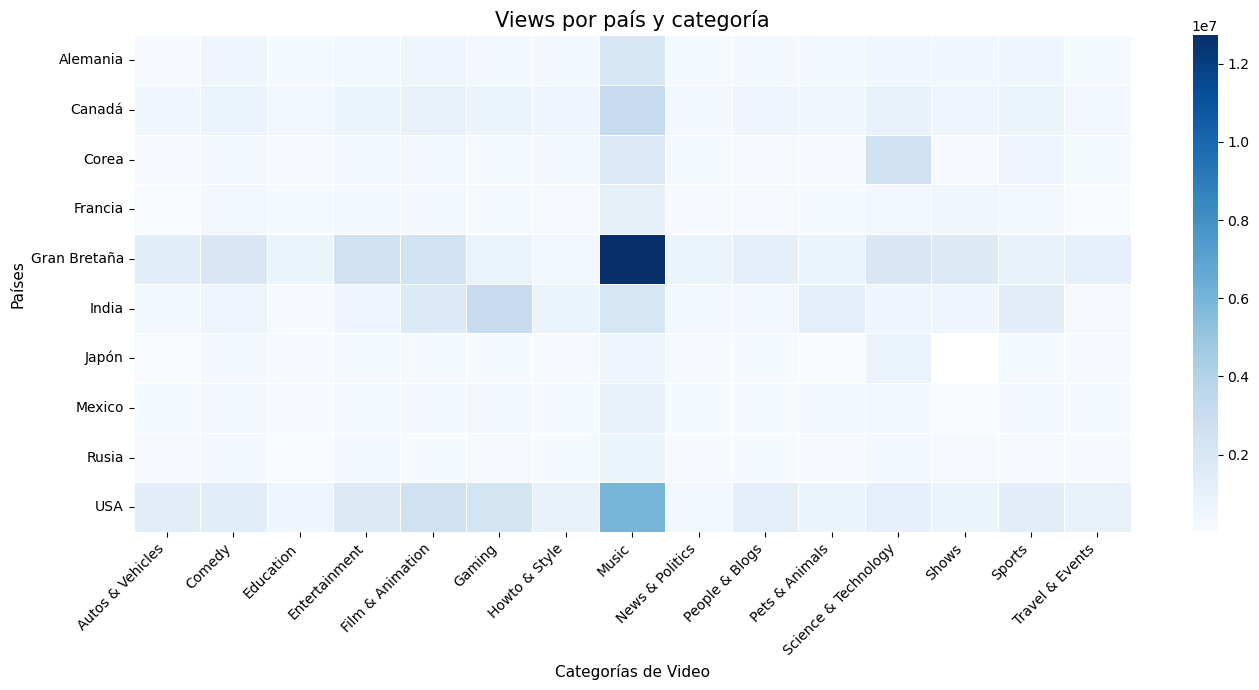

In [770]:
pivot_views = df.pivot_table(index="pais", columns="category", values="views")
plt.figure(figsize=(14, 7))

sns.heatmap(pivot_views, cmap="Blues", annot=False, linewidths=0.5)

plt.title("Views por país y categoría",fontsize=15)
plt.xlabel("Categorías de Video", fontsize=11)
plt.ylabel("Países", fontsize=11)
plt.xticks(rotation=45, ha="right") 

plt.tight_layout()
plt.show()

Vemos que las mayorias de visualizaciones se dan en Gran Bretaña y EEUU y que la categoría que más views suele tener es Music. El hecho de que un video sea de Gran Bretaña y de Musica puede ser relevante por ejemplo para el modelo, por lo que ambas categorías es bueno tenerlas en cuenta.

Vamos a desglosar comments_disabled	y ratings_disabled. Estas dos variables la mayoría del tiempo son False ya que lo normal es querer que la gente comente y haga like o dislike a tus videos. Vamos a ver en cuantos casos desactivaron ambas variables.

In [771]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]

In [772]:
Desactivadas.shape

(1421, 12)

In [773]:
Activadas = df[(df["comments_disabled"] == False) & (df["ratings_disabled"] == False)]

promedio_desactivadas = Desactivadas[["views"]].mean()# Calculamos el promedio de views para ambos grupos
promedio_activadas = Activadas[["views"]].mean()

# Juntamos ambos resultados en una pequeña tabla para compararlos
comparativa_directa = pd.DataFrame({"Ambas Activadas": promedio_activadas, "Ambas Desactivadas": promedio_desactivadas}).T #Transponemos para que se cambien columnas y filas

print(comparativa_directa)

                            views
Ambas Activadas     542451.836745
Ambas Desactivadas  466464.339901


Vemos que cuando los comentarios y los ratings están deshabilitados, los vídeos tienen menos visualizaciones de media (466.464 frente a 542.452). 

Una posible explicación es que el algoritmo de YouTube da más visibilidad a los vídeos que generan interacción (likes, dislikes y comentarios). Si el creador desactiva esas interacciones, el vídeo pierde señales de engagement y es menos recomendado. Además, este tipo de vídeos suele ser de nicho: canales de noticias o institucionales que evitan polémicas, contenido infantil o canales que prefieren no moderar comentarios. De hecho, entre los vídeos con ambas opciones desactivadas tiene más peso News & Politics (casi un 20 %) y destacan países como Japón, Francia e India.

Vimos que de media los videos suelen tardar unos 3 días en ser tendencia, aunque la mediana nos indica que suelen tardar alrededor de 1 dia. La dispersión es grande y se puede ver porque por ejemplo el vídeo máximo tardo 4215 dias en ser tendencia algo poco común.

### Conclusiones del análisis exploratorio

Las conclusiones que podemos sacar son las siguientes:
1. Existe una relación clara entre los views, los coments y los likes/dislikes.
2. Entertainment, People & Blogs y News & Politics son las categorías que más destacan.
3. Un mismo vídeo puede ser viral en varios países.
4. Los vídeos con los comentarios y los ratings desactivados tienen menos visualizaciones, probablemente porque al no generar interacción el algoritmo los recomienda menos.
5. Cruzando datos vemos que los videos que más views han tenido son de Musica fundamentalmente en Gran Bretaña. Tanto Gran Bretaña como el tipo Musica muestran ser una de las piezas fundamentales sobre las que giran las visualizaciones.

A continuación vamos a pasar a realizar punto por punto lo solicitado en los modelos.

## 3. Predicción de la categoría del vídeo

Vamos a utilizar los modelos conocidos de scikit-learn sobre el dataset limpio que cargamos desde el fichero pickle.

In [774]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer #lo usamo para ensamblar
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

Incluimos comment_count junto al resto de variables numéricas. No incluimos comments_disabled ni ratings_disabled porque son casi siempre False y apenas aportan información al modelo.

In [775]:
X = df[["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion", "pais"]]
y = df["category"]

In [776]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)#conserva proporcion entre particiones

In [777]:
le = LabelEncoder()
le.fit(ytrain)
ytrain = le.transform(ytrain)
ytest = le.transform(ytest)

In [778]:
encoder = OneHotEncoder(handle_unknown='ignore')#ignore: si al predecir aparece un país o categoría que no vio al entrenar (p. ej. en un pliegue de la validación cruzada o con datos nuevos), lo deja todo a 0 en vez de dar error
#Definimos el encoder para las variables que sean categoricas, en este caso solo será pais.

In [779]:
logaritmo = FunctionTransformer(np.log1p)
scaler = StandardScaler()
#Definimos las transformaciones numéricas para tratar los outliers

### Regresión Logística

La Regresión Logística aprende un peso (coeficiente) para cada variable y, en cada **iteración**, los corrige un poco para equivocarse menos con los datos de entrenamiento. Cuando las correcciones ya son mínimas, el modelo ha **convergido**: ha encontrado sus mejores coeficientes. `max_iter` es el número máximo de iteraciones; si se alcanza antes de converger, el modelo para igualmente y se queda **a medio ajustar** (con unos coeficientes que no son los mejores) y sklearn avisa con un `ConvergenceWarning`. Con las 100 iteraciones por defecto no le bastaba, así que lo subimos a 1000: si converge antes, para antes, así que no tarda más de lo necesario.

In [780]:
from sklearn.linear_model import LogisticRegression

In [781]:
lr = LogisticRegression(max_iter=1000)#con las 100 iteraciones por defecto no llegaba a converger (ConvergenceWarning) y se quedaba a medio ajustar; con 1000 sí converge

Creamos un pipeline numérico para incluirlo en el ensamblador de Column Transformer ya que según el modelo los outliers pueden o no ser relevantes de quitar.

In [782]:
pipeline_num = Pipeline([('log', logaritmo),('scaler', scaler)])

In [783]:
preprocess_lr = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [784]:
pipeline_lr = Pipeline(steps=[('preprocesamiento', preprocess_lr),
                              ('modelo', lr)])

In [785]:
pipeline_lr.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', LogisticRegression(max_iter=1000))])

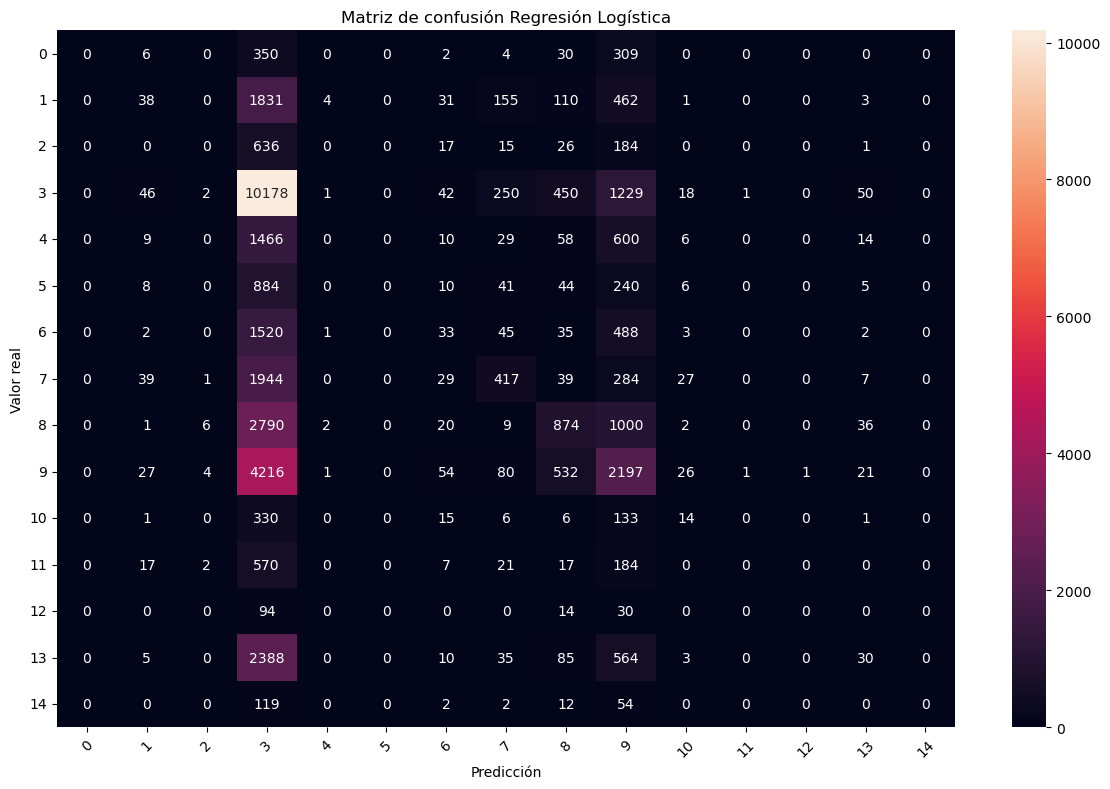

In [786]:
#Matriz confusión regresión logística.

y_pred_lr = pipeline_lr.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_lr)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos en la matriz que el modelo está muy descompensado hacia las clases 3 y 9. Es posible que haya un desbalanceo en el cual haya clases más dominantes y clases con menos registros y por ello, el modelo tienda a no predecir nunca las no dominantes. Lo podemos ver a continuación.

In [787]:
df["category"].value_counts()

category
Entertainment           61332
People & Blogs          35797
News & Politics         23701
Sports                  15597
Music                   13933
Comedy                  13177
Film & Animation        10961
Howto & Style           10645
Gaming                   6190
Education                4396
Science & Technology     4092
Autos & Vehicles         3506
Pets & Animals           2530
Travel & Events           947
Shows                     688
Name: count, dtype: int64

Más adelante haremos una comparativa de todas las matrices.

### Random Forest

En Random Forest no es necesario tratar los outliers ni escalar las variables, ya que los árboles dividen los datos por umbrales y no les afecta la magnitud de los valores. Por tanto, dejamos las variables numéricas tal cual.

In [788]:
from sklearn.ensemble import RandomForestClassifier

In [789]:
rf = RandomForestClassifier(random_state=42)

In [790]:
preprocess_rf = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("numericas", "passthrough",#"passthrough" es básicamente no aplicar ninguna transformación: esas columnas pasan tal cual al modelo.
     ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])
])

In [791]:
pipeline_rf = Pipeline(steps=[('preprocesamiento', preprocess_rf),
                              ('modelo', rf)])

In [792]:
pipeline_rf.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais']),
                                                 ('numericas', 'passthrough',
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', RandomForestClassifier(random_state=42))])

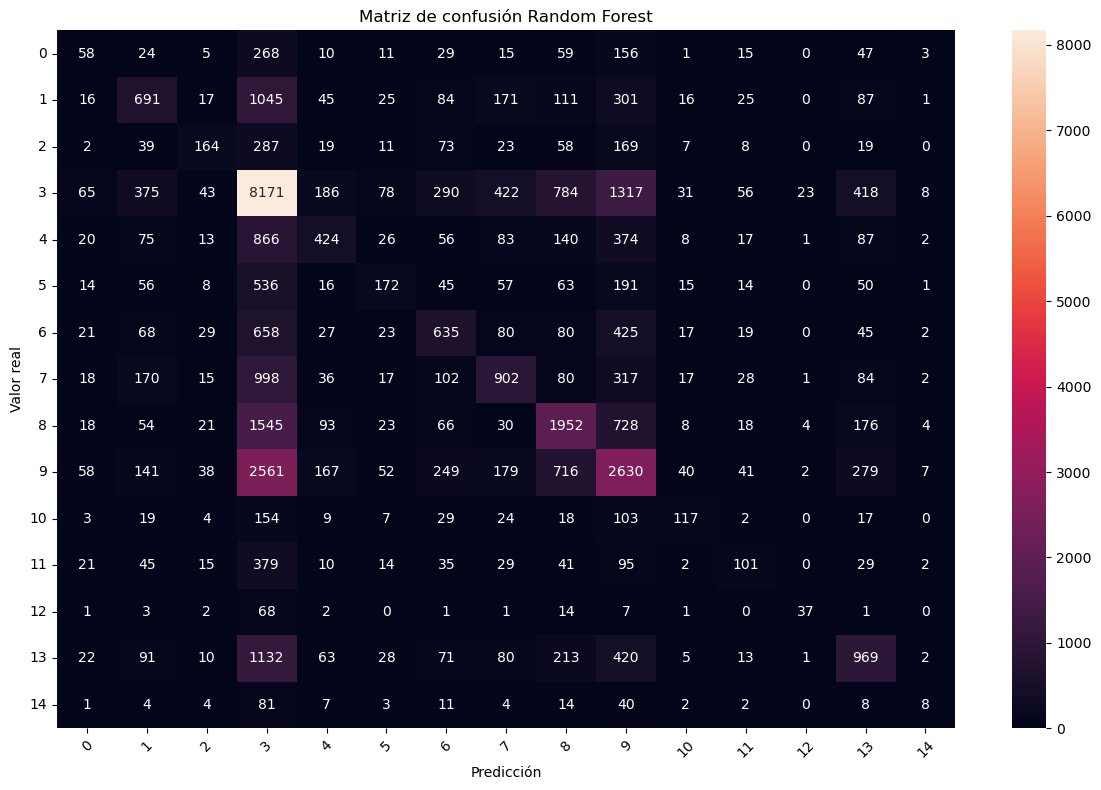

In [793]:
#Matriz de confusión random forest

y_pred_rf = pipeline_rf.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_rf)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### KNN

In [794]:
from sklearn.neighbors import KNeighborsClassifier

In [795]:
knn = KNeighborsClassifier()

In [796]:
preprocess_knn = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [797]:
pipeline_knn = Pipeline(steps=[('preprocesamiento', preprocess_knn),
                              ('modelo', knn)])

In [798]:
pipeline_knn.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', KNeighborsClassifier())])

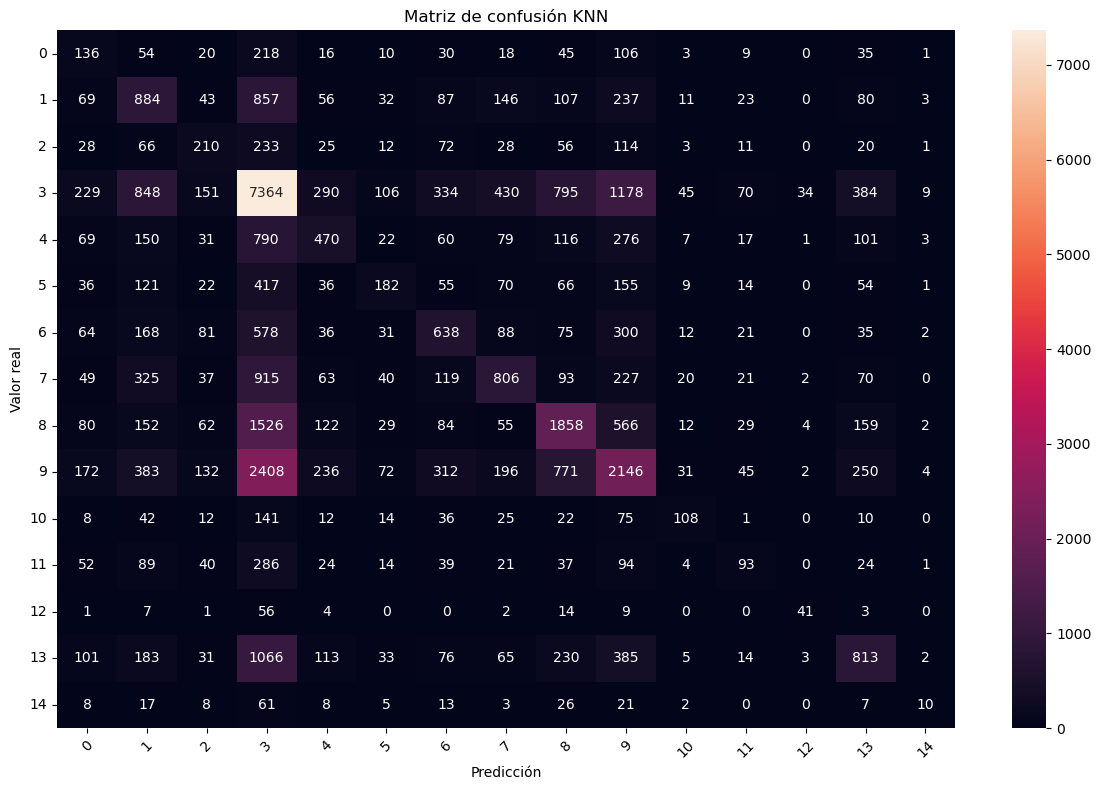

In [799]:
#Matriz de confusión KNN

y_pred_knn = pipeline_knn.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_knn)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### SVM

In [800]:
from sklearn.svm import SVC

In [801]:
svm = SVC(kernel='rbf', cache_size=1000, tol=1e-1, shrinking=True, max_iter=1000)  
# Tras varios intentos sabiendo que este no sería el modelo, optimizamos para que lo ejecute y se procese rápido
#Con max_iter=1000 el SVM para antes de converger (sale un ConvergenceWarning), así que sus resultados son algo peores de lo que daría bien ajustado. Sin ese límite tardaría horas

In [802]:
preprocess_svm = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [803]:
pipeline_svm = Pipeline(steps=[("preprocesamiento", preprocess_svm),
                              ("modelo", svm)])

In [804]:
pipeline_svm.fit(Xtrain, ytrain)

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', SVC(cache_size=1000, max_iter=1000, tol=0.1))])

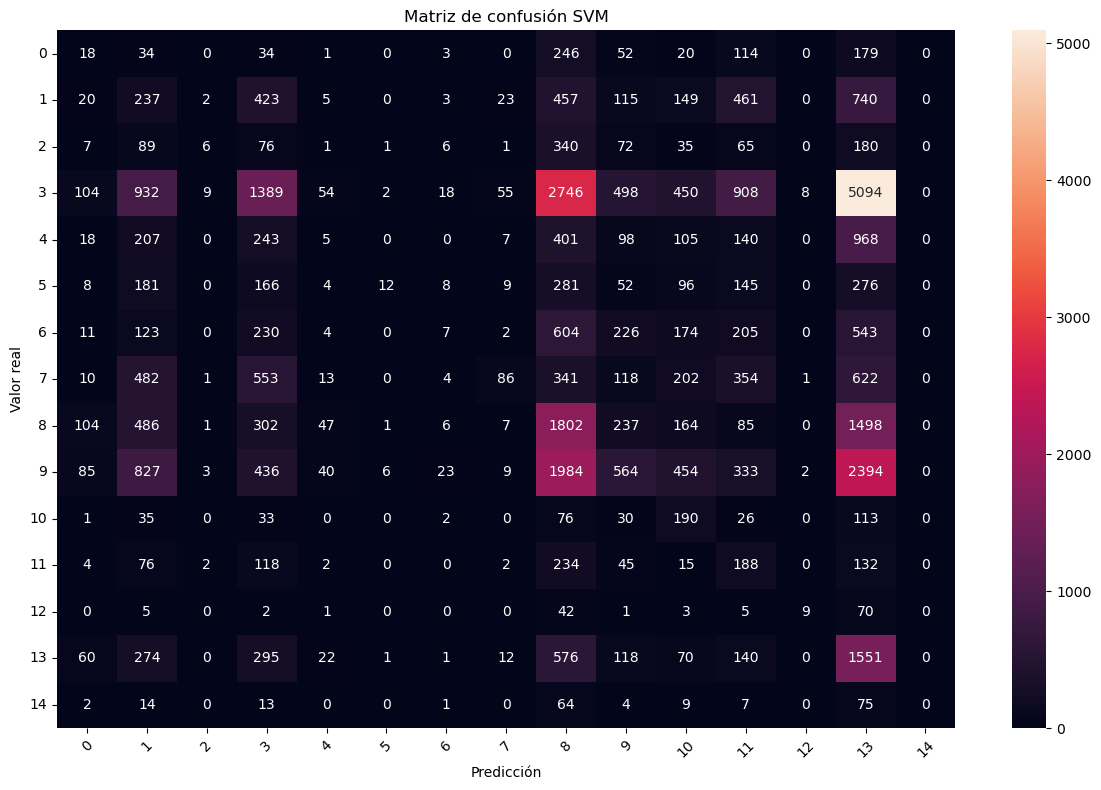

In [805]:
#Matriz de confusión SVM

y_pred_svm = pipeline_svm.predict(Xtest)
cm = confusion_matrix(ytest, y_pred_svm)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión SVM")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Resumen de las matrices de confusión

- **Regresión Logística:** predice casi siempre la clase 3 y, en menor medida, la 9. Prácticamente no acierta las clases minoritarias y algunas no las llega a predecir nunca.
- **Random Forest:** es el más equilibrado. Sigue favoreciendo la clase 3, pero predice todas las clases y acierta mejor la 8 y la 9.
- **KNN:** comportamiento muy parecido a Random Forest, algo peor en general, aunque reparte un poco más los aciertos entre clases.
- **SVM:** al no terminar de ajustarse, se desvía hacia las clases 13 y 8 y falla la mayoría del resto, por eso es el peor.

En todos los modelos el desbalanceo de clases hace que las clases mayoritarias dominen las predicciones.

Vistas las matrices de confusión, procedemos a comparar todas las métricas para ver los valores más altos.

In [806]:
#zero_division=0: si un modelo no predice nunca una clase, su precisión vale 0 en vez de dar un aviso
#output_dict=True: el informe sale como diccionario para coger cada métrica y montar la tabla
clasification = {
    "Modelo": ["Regresión Logística", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["accuracy"]
    ],
    "F1 Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["f1-score"]
    ],
    "F1 Weighted": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["weighted avg"]["f1-score"]
    ],
    "Recall Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_rf, zero_division=0,output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["macro avg"]["recall"]
    ],
    "Precision Macro": [
        classification_report(ytest, y_pred_lr, zero_division=0,output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["precision"]
    ]
}

df_clasification = pd.DataFrame(clasification)

metricas = ["Accuracy", "F1 Macro", "F1 Weighted", "Recall Macro", "Precision Macro"]

#ordenamos por F1 Macro porque da el mismo peso a todas las clases: si un modelo falla mucho en una clase
#con pocos casos, el F1 Macro baja y se nota; la accuracy podría salir alta solo por acertar la clase mayoritaria
df_clasification = df_clasification.sort_values(by="F1 Macro", ascending=False)

tabla_clasification = df_clasification.style#usamos esto para personalizar la tabla

for col in metricas:
    tabla_clasification = tabla_clasification.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_clasification.hide()#ocultamos el indice

Modelo,Accuracy,F1 Macro,F1 Weighted,Recall Macro,Precision Macro
Random Forest,0.410395,0.293292,0.390884,0.260452,0.371098
KNN,0.379744,0.281494,0.368319,0.263229,0.330483
Regresión Logística,0.332080,0.090639,0.242494,0.102518,0.132705
SVM,0.146124,0.084028,0.125399,0.127226,0.189490


Elegimos el modelo Random Forest. Procedemos a optimizarlo con RandomizedSearchCV en lugar de GridSearchCV, ya que al intentarlo con Grid el coste computacional era enorme.

In [807]:
from sklearn.model_selection import RandomizedSearchCV #No utilizamos Grid ya que al intentarlos el coste computacional era enorme 
from sklearn.metrics import f1_score, classification_report 

In [808]:
param_dist = {
    "modelo__n_estimators": [100, 150],
    "modelo__criterion": ["gini", "entropy"],#no utilizamos log_loss porque se basan en la misma medida
    "modelo__max_depth": [12, 20, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", 0.5],
    "modelo__class_weight": [None, "balanced", "balanced_subsample"],
    "modelo__bootstrap": [True],
    "modelo__max_samples": [0.7, 0.8]
}

grid_search_rf = RandomizedSearchCV(
    estimator=pipeline_rf,         
    param_distributions=param_dist,
    n_iter=12,
    scoring="f1_macro",
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    random_state=42,
    refit=True
)

grid_search_rf.fit(Xtrain, ytrain)

rf_optimo = grid_search_rf.best_estimator_#mejor versión ya entrenada

print("Best parameters:", grid_search_rf.best_params_)
print("Best CV f1_macro:", grid_search_rf.best_score_)

y_pred_train_rf_optimo = rf_optimo.predict(Xtrain)
y_pred_test_rf_optimo = rf_optimo.predict(Xtest)

print("\nTrain f1_macro:", f1_score(ytrain, y_pred_train_rf_optimo, average="macro"))
print(classification_report(ytrain, y_pred_train_rf_optimo))

print("\nTest f1_macro:", f1_score(ytest, y_pred_test_rf_optimo, average="macro"))
print(classification_report(ytest, y_pred_test_rf_optimo))

Fitting 2 folds for each of 12 candidates, totalling 24 fits
Best parameters: {'modelo__n_estimators': 150, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 1, 'modelo__max_samples': 0.8, 'modelo__max_features': 'log2', 'modelo__max_depth': 20, 'modelo__criterion': 'gini', 'modelo__class_weight': 'balanced_subsample', 'modelo__bootstrap': True}
Best CV f1_macro: 0.3074464018188881

Train f1_macro: 0.8254326315720124
              precision    recall  f1-score   support

           0       0.47      0.98      0.64      2805
           1       0.84      0.89      0.86     10542
           2       0.76      0.95      0.85      3517
           3       0.94      0.79      0.86     49065
           4       0.79      0.88      0.83      8769
           5       0.83      0.93      0.88      4952
           6       0.64      0.92      0.75      8516
           7       0.92      0.87      0.89     11146
           8       0.83      0.87      0.85     18961
           9       0.94     

Añadimos el Random Forest optimizado a la tabla comparativa para ver la mejora respecto al resto de modelos.

In [809]:
report_rf_optimo = classification_report(ytest, y_pred_test_rf_optimo, zero_division=0, output_dict=True)

fila_rf_optimo = pd.DataFrame({
    "Modelo": ["Random Forest optimizado"],
    "Accuracy": [report_rf_optimo["accuracy"]],
    "F1 Macro": [report_rf_optimo["macro avg"]["f1-score"]],
    "F1 Weighted": [report_rf_optimo["weighted avg"]["f1-score"]],
    "Recall Macro": [report_rf_optimo["macro avg"]["recall"]],
    "Precision Macro": [report_rf_optimo["macro avg"]["precision"]]
})

df_comparativa = pd.concat([df_clasification, fila_rf_optimo], ignore_index=True)

df_comparativa = df_comparativa.sort_values(by="F1 Macro", ascending=False)

tabla_comparativa = df_comparativa.style

for col in metricas:
    tabla_comparativa = tabla_comparativa.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_comparativa.hide()#ocultamos el indice

Modelo,Accuracy,F1 Macro,F1 Weighted,Recall Macro,Precision Macro
Random Forest optimizado,0.388178,0.322941,0.390300,0.344021,0.313316
Random Forest,0.410395,0.293292,0.390884,0.260452,0.371098
KNN,0.379744,0.281494,0.368319,0.263229,0.330483
Regresión Logística,0.332080,0.090639,0.242494,0.102518,0.132705
SVM,0.146124,0.084028,0.125399,0.127226,0.189490


Tras la optimización con RandomizedSearchCV, el mejor modelo obtiene un F1 Macro en test de 0,32 frente al 0,29 del Random Forest por defecto, por lo que la optimización mejora el modelo, sobre todo en la detección de las categorías minoritarias gracias a class_weight="balanced_subsample". A cambio, la accuracy baja ligeramente (0,39 frente a 0,41), ya que el modelo deja de predecir con tanta frecuencia las categorías mayoritarias como Entertainment. Aun así, el modelo presenta sobreajuste: el F1 Macro en train es 0,83 frente a 0,32 en test. En general, con las variables numéricas disponibles es difícil predecir la categoría de un vídeo con gran precisión.

## 4. Reto opcional: comentarios o ratings desactivados

**Enunciado:** Crear un algoritmo de clasificación que intente averiguar lo mejor posible si los comentarios o los ratings estarán deshabilitados por parte del creador del vídeo en base al resto de la información. Al ser una clasificación altamente desbalanceada se valorará no solo obtener una alta precisión, sino también estudiar en una matriz de confusión si se sega excesivamente hacia la clase mayoritaria y en el caso de que ocurra intentar mitigar este hecho.

Vimos en el EDA, al comparar los vídeos con los comentarios y los ratings activados y desactivados, que los vídeos con ambas opciones desactivadas tienen menos visualizaciones. Esto nos dice algo importante sobre qué variables podemos usar.

Por un lado, views mide el alcance del vídeo y existe independientemente de la decisión del creador: un vídeo sigue acumulando visualizaciones tenga o no los comentarios y los ratings desactivados. Por eso sí nos puede ayudar a predecir.

Por otro lado, likes, dislikes y comment_count no miden lo mismo en estos vídeos. Si el creador desactiva los comentarios, el público no puede comentar y comment_count se queda en 0. Si desactiva los ratings, no se puede dar like ni dislike, y likes y dislikes se quedan en 0. Es decir, en estos vídeos esas variables no reflejan cómo de popular es el vídeo, sino directamente la decisión que queremos predecir. Usarlas sería como darle la respuesta al modelo.

En el EDA creamos el dataframe Desactivadas con los vídeos que tenían los comentarios y los ratings desactivados. Si miramos sus likes, dislikes y comment_count, vemos que todos valen 0:

In [810]:
Desactivadas[["likes", "dislikes", "comment_count"]].max()

likes            0
dislikes         0
comment_count    0
dtype: int64

Pero en el reto queremos predecir si están desactivados los comentarios o los ratings, no solo ambos a la vez. Comprobamos qué pasa en cada caso por separado:

In [811]:
print(df[df["comments_disabled"] == True]["comment_count"].max())
print(df[df["ratings_disabled"] == True][["likes", "dislikes"]].max())

0
likes       0
dislikes    0
dtype: int64


Por tanto, likes, dislikes y comment_count no nos sirven para predecir: no son una causa de que el creador desactive los comentarios o los ratings, sino una consecuencia. Si las usáramos, el modelo acertaría casi siempre, pero sería hacer trampa, ya que con un vídeo nuevo no sabríamos esos valores antes de que el creador tomara la decisión. Por eso usamos solo views, dias_desde_publicacion, pais y category.

In [812]:
X_reto = df[["views", "dias_desde_publicacion", "pais", "category"]]
y_reto = (df["comments_disabled"] | df["ratings_disabled"]).astype(int)#1 si tiene desactivados los comentarios o los ratings, 0 si no. Al pasarlo a int ya es numérico, por lo que no necesitamos LabelEncoder

In [813]:
print(y_reto.value_counts())

0    199388
1      8104
Name: count, dtype: int64


En y_reto, el valor 1 indica que el vídeo tiene desactivados los comentarios, los ratings o ambos, y el valor 0 que tiene las dos opciones activadas.

In [814]:
Xtrain_reto, Xtest_reto, ytrain_reto, ytest_reto = train_test_split(X_reto, y_reto, test_size=0.2, random_state=42, stratify=y_reto)#conserva proporcion entre particiones

### Regresión Logística

In [815]:
lr_reto = LogisticRegression(max_iter=1000)#igual que antes: con 1000 iteraciones llega a converger

In [816]:
preprocess_lr_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [817]:
pipeline_lr_reto = Pipeline(steps=[('preprocesamiento', preprocess_lr_reto),
                                   ('modelo', lr_reto)])

In [818]:
pipeline_lr_reto.fit(Xtrain_reto, ytrain_reto)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views',
                                                   'dias_desde_publicacion'])])),
                ('modelo', LogisticRegression(max_iter=1000))])

In [819]:
y_pred_lr_reto = pipeline_lr_reto.predict(Xtest_reto)

### Random Forest

In [820]:
rf_reto = RandomForestClassifier(random_state=42)

In [821]:
preprocess_rf_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("numericas", "passthrough", ["views", "dias_desde_publicacion"])])

In [822]:
pipeline_rf_reto = Pipeline(steps=[('preprocesamiento', preprocess_rf_reto),
                                   ('modelo', rf_reto)])

In [823]:
pipeline_rf_reto.fit(Xtrain_reto, ytrain_reto)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('numericas', 'passthrough',
                                                  ['views',
                                                   'dias_desde_publicacion'])])),
                ('modelo', RandomForestClassifier(random_state=42))])

In [824]:
y_pred_rf_reto = pipeline_rf_reto.predict(Xtest_reto)

### KNN

In [825]:
knn_reto = KNeighborsClassifier()

In [826]:
preprocess_knn_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [827]:
pipeline_knn_reto = Pipeline(steps=[('preprocesamiento', preprocess_knn_reto),
                                    ('modelo', knn_reto)])

In [828]:
pipeline_knn_reto.fit(Xtrain_reto, ytrain_reto)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views',
                                                   'dias_desde_publicacion'])])),
                ('modelo', KNeighborsClassifier())])

In [829]:
y_pred_knn_reto = pipeline_knn_reto.predict(Xtest_reto)

### SVM

In [830]:
svm_reto = SVC(kernel='rbf', cache_size=1000, tol=1e-1, shrinking=True, max_iter=1000)#mismos parámetros que antes para que sea rápido: tampoco llega a converger

In [831]:
preprocess_svm_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [832]:
pipeline_svm_reto = Pipeline(steps=[('preprocesamiento', preprocess_svm_reto),
                                    ('modelo', svm_reto)])

In [833]:
pipeline_svm_reto.fit(Xtrain_reto, ytrain_reto)

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views',
                                                   'dias_desde_publicacion'])])),
                ('modelo', SVC(cache_size=1000, max_iter=1000, tol=0.1))])

In [834]:
y_pred_svm_reto = pipeline_svm_reto.predict(Xtest_reto)

Comparamos las métricas de los cuatro modelos. Al estar las clases tan desbalanceadas nos fijamos sobre todo en las métricas de la clase 1 (vídeos con comentarios o ratings desactivados), ya que la accuracy puede salir alta aunque el modelo no detecte ninguno.

In [835]:
#["1"] = métricas de la clase 1 (comentarios o ratings desactivados), la minoritaria que queremos detectar
clasification_reto = {
    "Modelo": ["Regresión Logística", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["accuracy"]
    ],
    "F1 Macro": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"]
    ],
    "Recall clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["recall"]
    ],
    "Precision clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["precision"]
    ],
    "F1 clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["f1-score"]
    ]
}

df_clasification_reto = pd.DataFrame(clasification_reto)

metricas_reto = ["Accuracy", "F1 Macro", "Recall clase 1", "Precision clase 1", "F1 clase 1"]

df_clasification_reto = df_clasification_reto.sort_values(by="F1 clase 1", ascending=False)

tabla_clasification_reto = df_clasification_reto.style

for col in metricas_reto:
    tabla_clasification_reto = tabla_clasification_reto.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_clasification_reto.hide()#ocultamos el indice

Modelo,Accuracy,F1 Macro,Recall clase 1,Precision clase 1,F1 clase 1
Random Forest,0.932721,0.529872,0.090068,0.099795,0.094682
SVM,0.865852,0.497849,0.125231,0.046645,0.067973
KNN,0.958818,0.521766,0.036397,0.286408,0.064587
Regresión Logística,0.960939,0.490040,0.000000,0.000000,0.000000


Vemos que todos los modelos están sesgados hacia la clase mayoritaria. El caso más claro es la Regresión Logística, que tiene la accuracy más alta (96 %) pero no detecta ningún vídeo con los comentarios o los ratings desactivados, ya que predice siempre 0. Elegimos Random Forest porque es el que obtiene mejor F1 en la clase 1, aunque solo detecta un 9 % de estos vídeos. A continuación intentaremos mitigar este sesgo.

Optimizamos el Random Forest con GridSearchCV. A diferencia de la predicción de categoría, aquí no buscamos entre muchos parámetros, sino que nos centramos en los que afectan directamente al desbalanceo de clases. Como son pocas combinaciones, podemos probarlas todas con Grid sin un coste computacional excesivo:

- class_weight: con "balanced" el modelo da más peso a los errores en la clase minoritaria (1), de forma inversamente proporcional a su frecuencia. Así deja de compensarle predecir siempre 0.
- min_samples_leaf: número mínimo de vídeos en cada hoja del árbol. Con 1, los árboles crecen hasta memorizar cada vídeo y el peso de las clases apenas influye. Con hojas más grandes, cada hoja agrupa varios vídeos y el peso de la clase minoritaria sí cambia la decisión.
- max_depth: profundidad máxima de los árboles. Limitarla tiene un efecto parecido al anterior, ya que evita que los árboles memoricen los datos de entrenamiento.

Como métrica usamos el F1 de la clase 1, ya que es la clase que queremos detectar.

In [836]:
from sklearn.model_selection import GridSearchCV

param_grid_reto = {
    "modelo__class_weight": [None, "balanced"],
    "modelo__min_samples_leaf": [1, 20, 50],
    "modelo__max_depth": [12, None]
}

grid_search_rf_reto = GridSearchCV(
    estimator=pipeline_rf_reto,
    param_grid=param_grid_reto,
    scoring="f1",#f1 de la clase 1
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    refit=True
)

grid_search_rf_reto.fit(Xtrain_reto, ytrain_reto)

rf_optimo_reto = grid_search_rf_reto.best_estimator_

print("Best parameters:", grid_search_rf_reto.best_params_)
print("Best CV f1 clase 1:", grid_search_rf_reto.best_score_)

y_pred_train_reto = rf_optimo_reto.predict(Xtrain_reto)
y_pred_test_reto = rf_optimo_reto.predict(Xtest_reto)

print("\nTrain f1 clase 1:", f1_score(ytrain_reto, y_pred_train_reto))
print(classification_report(ytrain_reto, y_pred_train_reto))

print("\nTest f1 clase 1:", f1_score(ytest_reto, y_pred_test_reto))
print(classification_report(ytest_reto, y_pred_test_reto))

Fitting 2 folds for each of 12 candidates, totalling 24 fits
Best parameters: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 20}
Best CV f1 clase 1: 0.16446161310334242

Train f1 clase 1: 0.2317759707453207
              precision    recall  f1-score   support

           0       0.99      0.81      0.89    159510
           1       0.14      0.74      0.23      6483

    accuracy                           0.81    165993
   macro avg       0.56      0.78      0.56    165993
weighted avg       0.95      0.81      0.86    165993


Test f1 clase 1: 0.16539317148660412
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     39878
           1       0.10      0.53      0.17      1621

    accuracy                           0.79     41499
   macro avg       0.54      0.67      0.52     41499
weighted avg       0.94      0.79      0.85     41499



Con GridSearchCV el mejor modelo usa class_weight="balanced", min_samples_leaf=20 y sin límite de profundidad, lo que confirma que el peso de la clase minoritaria solo tiene efecto cuando las hojas agrupan varios vídeos. El recall de la clase 1 pasa del 9 % al 52 %, es decir, ahora el modelo detecta más de la mitad de los vídeos con los comentarios o los ratings desactivados, y el F1 de la clase 1 sube de 0,09 a 0,16. A cambio, la accuracy baja del 93 % al 79 %, ya que el modelo deja de predecir siempre la clase mayoritaria y aparecen más falsos positivos. La precisión se mantiene en torno al 10 %, lo que indica que, sin las variables que delatan la respuesta, la información disponible para predecir esta decisión del creador es limitada. Además, el F1 en validación cruzada (0,165) y en test (0,162) es muy parecido, por lo que el resultado es estable.

Comparamos las matrices de confusión del Random Forest base y del optimizado con Grid para ver si el modelo se sesga hacia la clase mayoritaria y si hemos conseguido mitigarlo.

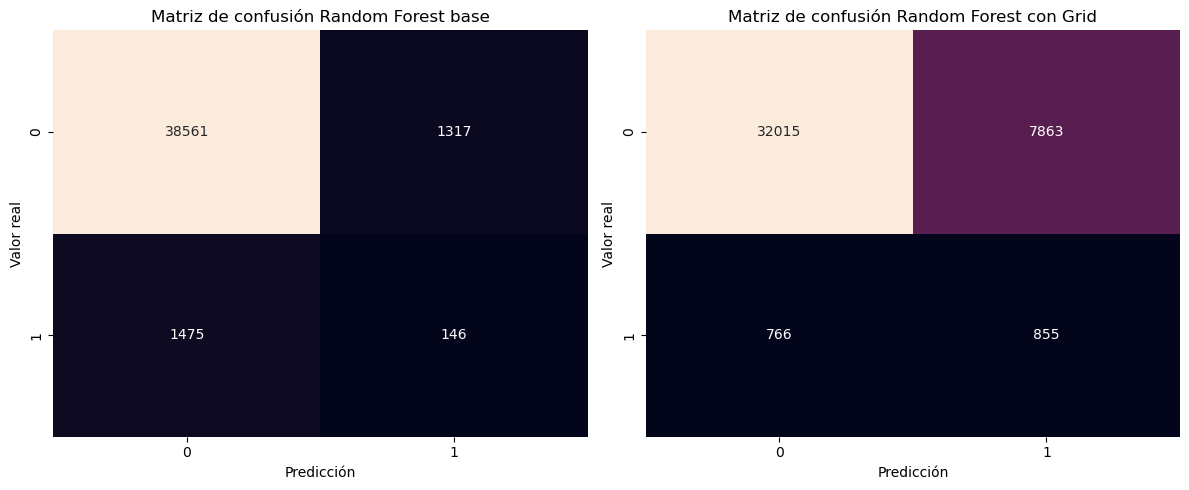

In [837]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(ytest_reto, y_pred_rf_reto), annot=True, fmt="d", cbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión Random Forest base")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Valor real")

sns.heatmap(confusion_matrix(ytest_reto, y_pred_test_reto), annot=True, fmt="d", cbar=False, ax=axes[1])
axes[1].set_title("Matriz de confusión Random Forest con Grid")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Valor real")

plt.tight_layout()
plt.show()

### Conclusiones de las matrices de confusión

- **Random Forest base:** el modelo está claramente sesgado hacia la clase mayoritaria. De los 1.621 vídeos con los comentarios o los ratings desactivados, solo detecta 146 y clasifica como 0 los otros 1.475.
- **Random Forest con Grid:** el sesgo se mitiga. Detecta 841 de los 1.621 vídeos desactivados, más de la mitad, y los que se le escapan bajan de 1.475 a 780.
- **El coste:** los falsos positivos, es decir, vídeos con todo activado que el modelo marca como desactivados, suben de 1.317 a 7.890. Por eso baja la accuracy.

En resumen, hemos conseguido que el modelo deje de ignorar la clase minoritaria, a cambio de más falsas alarmas. Si el objetivo es detectar los vídeos en los que el creador desactivará los comentarios o los ratings, es preferible un modelo que detecte más de la mitad de ellos aunque se equivoque más, que uno con mayor accuracy que apenas detecta ninguno.

## 5. Predicción del número de likes

En el reto vimos que, cuando los ratings están desactivados, los likes valen siempre 0, ya que el público no puede darle a "Me gusta". En estos vídeos no hay unos likes que predecir, por lo que los eliminamos de este apartado. Si los dejáramos y usáramos ratings_disabled como variable, sería darle la respuesta al modelo, igual que explicamos en el reto.

In [838]:
df_likes = df[df["ratings_disabled"] == False]
X_likes = df_likes[["views", "comment_count", "dislikes", "dias_desde_publicacion", "comments_disabled", "pais", "category"]]
y_likes = df_likes["likes"]

In [839]:
Xtrain_likes, Xtest_likes, ytrain_likes, ytest_likes = train_test_split(X_likes, y_likes, test_size=0.2, random_state=42)

Igual que en la predicción de categoría, aplicamos el logaritmo y el StandardScaler a las variables numéricas en el preprocess de los modelos que lo necesitan, para tratar los outliers y que todas queden en la misma escala. La variable likes la dejamos tal cual, ya que es lo que queremos predecir.

### Regresión Lineal

In [840]:
from sklearn.linear_model import LinearRegression

In [841]:
lr_likes = LinearRegression()

In [842]:
preprocess_lr_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "comment_count", "dislikes", "dias_desde_publicacion"]),
    ("booleana", "passthrough", ["comments_disabled"])])#el ColumnTransformer tira las columnas que no se le nombran, así que la pasamos tal cual con passthrough. No la metemos en num_procesadas porque solo vale 0 o 1: no tiene outliers ni escala que corregir

In [843]:
pipeline_lr_likes = Pipeline(steps=[("preprocesamiento", preprocess_lr_likes),
                                    ("modelo", lr_likes)])

In [844]:
pipeline_lr_likes.fit(Xtrain_likes, ytrain_likes)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'comment_count',
                                                   'dislikes',
                                                   'dias_desde_publicacion']),
                                                 ('booleana', 'passthrough',
                                                  ['comments_disabled'])])),
                ('modelo', LinearRegression())])

In [845]:
y_pred_lr_likes = pipeline_lr_likes.predict(Xtest_likes)

### Perceptrón Multicapa

In [846]:
from sklearn.neural_network import MLPRegressor

In [847]:
mlp_likes = MLPRegressor(random_state=42)

In [848]:
preprocess_mlp_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "comment_count", "dislikes", "dias_desde_publicacion"]),
    ("booleana", "passthrough", ["comments_disabled"])])

In [849]:
pipeline_mlp_likes = Pipeline(steps=[("preprocesamiento", preprocess_mlp_likes),
                                     ("modelo", mlp_likes)])

In [850]:
pipeline_mlp_likes.fit(Xtrain_likes, ytrain_likes)

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'comment_count',
                                                   'dislikes',
                                                   'dias_desde_publicacion']),
                                                 ('booleana', 'passthrough',
                                                  ['comments_disabled'])])),
                ('modelo', MLPRegressor(random_state=42))])

In [851]:
y_pred_mlp_likes = pipeline_mlp_likes.predict(Xtest_likes)

### Random Forest

In [852]:
from sklearn.ensemble import RandomForestRegressor

In [853]:
rf_likes = RandomForestRegressor(random_state=42)

En Random Forest no es necesario tratar los outliers ni escalar las variables, ya que los árboles dividen los datos por umbrales y no les afecta la magnitud de los valores. Por tanto, dejamos las variables numéricas tal cual.

In [854]:
preprocess_rf_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("numericas", "passthrough", ["views", "comment_count", "dislikes", "dias_desde_publicacion", "comments_disabled"])])

In [855]:
pipeline_rf_likes = Pipeline(steps=[("preprocesamiento", preprocess_rf_likes),
                                    ("modelo", rf_likes)])

In [856]:
pipeline_rf_likes.fit(Xtrain_likes, ytrain_likes)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['pais', 'category']),
                                                 ('numericas', 'passthrough',
                                                  ['views', 'comment_count',
                                                   'dislikes',
                                                   'dias_desde_publicacion',
                                                   'comments_disabled'])])),
                ('modelo', RandomForestRegressor(random_state=42))])

In [857]:
y_pred_rf_likes = pipeline_rf_likes.predict(Xtest_likes)

Comparamos las métricas de los tres modelos. Al ser una regresión no usamos classification_report, sino métricas que miden cuánto se aleja la predicción del valor real:

- MAE: error medio en número de likes.
- RMSE: parecido al MAE, pero castiga más los errores grandes.
- R2: proporción de la variación de los likes que explica el modelo (1 es perfecto, 0 es como predecir siempre la media).

In [858]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [859]:
regresion = {
    "Modelo": ["Regresión Lineal", "Perceptrón Multicapa", "Random Forest"],
    "MAE": [
        mean_absolute_error(ytest_likes, y_pred_lr_likes),
        mean_absolute_error(ytest_likes, y_pred_mlp_likes),
        mean_absolute_error(ytest_likes, y_pred_rf_likes)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(ytest_likes, y_pred_lr_likes)),
        np.sqrt(mean_squared_error(ytest_likes, y_pred_mlp_likes)),
        np.sqrt(mean_squared_error(ytest_likes, y_pred_rf_likes))
    ],
    "R2": [
        r2_score(ytest_likes, y_pred_lr_likes),
        r2_score(ytest_likes, y_pred_mlp_likes),
        r2_score(ytest_likes, y_pred_rf_likes)
    ]
}

df_regresion = pd.DataFrame(regresion)

df_regresion = df_regresion.sort_values(by="R2", ascending=False)

tabla_regresion = df_regresion.style

tabla_regresion = tabla_regresion.highlight_min(subset=["MAE", "RMSE"], props="font-weight: bold; font-size: 16px;")#en MAE y RMSE cuanto menor mejor
tabla_regresion = tabla_regresion.highlight_max(subset=["R2"], props="font-weight: bold; font-size: 16px;")#en R2 cuanto mayor mejor

tabla_regresion.hide()#ocultamos el indice

Modelo,MAE,RMSE,R2
Random Forest,4903.144225,21772.130282,0.949349
Perceptrón Multicapa,11377.263447,65600.310501,0.540173
Regresión Lineal,27176.575228,88288.487620,0.167104


### Conclusiones de la comparativa

- **Random Forest:** es el que mejor predice. Acierta el 95 % del comportamiento de los likes y, de media, se equivoca en unos 4.900 likes por vídeo.
- **Perceptrón Multicapa:** acierta algo más de la mitad (54 %) y se equivoca en unos 11.400 likes de media, más del doble que Random Forest.
- **Regresión Lineal:** es el que peor predice. Solo acierta el 17 % y se equivoca en unos 27.000 likes de media. Esto pasa porque los likes no suben de forma proporcional al resto de variables, y una recta no es capaz de seguir esa relación.

En los tres modelos el RMSE es mucho más alto que el MAE. Esto quiere decir que en la mayoría de vídeos el modelo se acerca bastante, pero en unos pocos vídeos virales con millones de likes falla por mucho.

Nos quedamos con Random Forest y vamos a buscar la mejor combinación de sus parámetros. Igual que en la predicción de categoría, usamos RandomizedSearchCV, que prueba solo algunas combinaciones al azar, en lugar de GridSearchCV, que las prueba todas y tardaría demasiado. Para elegir la mejor combinación nos fijamos en el R2.

In [860]:
param_dist_likes = {
    "modelo__n_estimators": [100, 150],
    "modelo__max_depth": [12, 20, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", 0.5, 1.0],
    "modelo__bootstrap": [True],
    "modelo__max_samples": [0.7, 0.8]
}

random_search_rf_likes = RandomizedSearchCV(
    estimator=pipeline_rf_likes,
    param_distributions=param_dist_likes,
    n_iter=12,
    scoring="r2",
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    random_state=42,
    refit=True
)

random_search_rf_likes.fit(Xtrain_likes, ytrain_likes)

rf_optimo_likes = random_search_rf_likes.best_estimator_

print("Best parameters:", random_search_rf_likes.best_params_)
print("Best CV R2:", random_search_rf_likes.best_score_)

y_pred_train_likes = rf_optimo_likes.predict(Xtrain_likes)
y_pred_test_likes = rf_optimo_likes.predict(Xtest_likes)

print("\nTrain R2:", r2_score(ytrain_likes, y_pred_train_likes))
print("Train MAE:", mean_absolute_error(ytrain_likes, y_pred_train_likes))

print("\nTest R2:", r2_score(ytest_likes, y_pred_test_likes))
print("Test MAE:", mean_absolute_error(ytest_likes, y_pred_test_likes))

Fitting 2 folds for each of 12 candidates, totalling 24 fits
Best parameters: {'modelo__n_estimators': 100, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 1, 'modelo__max_samples': 0.8, 'modelo__max_features': 1.0, 'modelo__max_depth': None, 'modelo__bootstrap': True}
Best CV R2: 0.9085051911221411

Train R2: 0.9882670472942343
Train MAE: 2205.9982722690534

Test R2: 0.9448399328983037
Test MAE: 4993.241965148378


Añadimos el Random Forest optimizado a la tabla comparativa para ver la mejora respecto al resto de modelos.

In [861]:
fila_rf_optimo_likes = pd.DataFrame({
    "Modelo": ["Random Forest optimizado"],
    "MAE": [mean_absolute_error(ytest_likes, y_pred_test_likes)],
    "RMSE": [np.sqrt(mean_squared_error(ytest_likes, y_pred_test_likes))],
    "R2": [r2_score(ytest_likes, y_pred_test_likes)]
})

df_comparativa_likes = pd.concat([df_regresion, fila_rf_optimo_likes], ignore_index=True)

df_comparativa_likes = df_comparativa_likes.sort_values(by="R2", ascending=False)

tabla_comparativa_likes = df_comparativa_likes.style

tabla_comparativa_likes = tabla_comparativa_likes.highlight_min(subset=["MAE", "RMSE"], props="font-weight: bold; font-size: 16px;")
tabla_comparativa_likes = tabla_comparativa_likes.highlight_max(subset=["R2"], props="font-weight: bold; font-size: 16px;")

tabla_comparativa_likes.hide()#ocultamos el indice

Modelo,MAE,RMSE,R2
Random Forest,4903.144225,21772.130282,0.949349
Random Forest optimizado,4993.241965,22720.663640,0.944840
Perceptrón Multicapa,11377.263447,65600.310501,0.540173
Regresión Lineal,27176.575228,88288.487620,0.167104


### Conclusiones de la optimización

El Random Forest optimizado no mejora al Random Forest por defecto: obtiene un R2 en test de 0,945 frente a 0,949 y un MAE de unos 5.000 likes frente a 4.900. La diferencia es muy pequeña, pero indica que los parámetros por defecto ya eran prácticamente los mejores para este problema (de hecho, la búsqueda elige árboles sin límite de profundidad, min_samples_leaf=1 y todas las variables en cada división, que es muy parecido a lo que hace el modelo por defecto). Además, la búsqueda solo prueba 12 combinaciones con cv=2, por lo que no recorre todo el espacio de parámetros.

El modelo presenta algo de sobreajuste (R2 de 0,988 en train frente a 0,945 en test), aunque mucho menor que en la predicción de categoría, y el resultado en test sigue siendo muy bueno.

Nos quedamos con el **Random Forest por defecto**, que es el que mejores métricas tiene. A diferencia de la categoría, el número de likes sí se puede predecir con gran precisión, ya que, como vimos en la matriz de correlación, está muy relacionado con views, comment_count y dislikes.

## 6. Clusterización

**Enunciado:** Intentar encontrar grupos en los vídeos mediante diversas técnicas de clusterización. Evaluar cómo se superpone cada una con respecto a las categorías de los vídeos. Utilizar las técnicas de reducción de dimensionalidad.

Para este apartado utilizaremos los siguientes modelos de clusterización:

- K-Means
- DBSCAN
- Gaussian Mixture Models (GMM)
- HDBSCAN
- Mean-Shift

Igual que en clasificación y regresión, primero entrenamos cada modelo con los valores por defecto de su clase, salvo cuando no sea viable (lo explicamos en cada caso), elegimos el mejor y después lo optimizamos.

### Reducción de dimensionalidad

Antes de clusterizar elegiremos entre una de las siguientes técnicas de reducción de dimensionalidad:

- PCA
- t-SNE
- LDA

Usamos las variables numéricas (views, likes, dislikes, comment_count y dias_desde_publicacion) y añadimos algunas nuevas sacadas de las variables de texto, que nos dan información sobre el contenido y el estilo del vídeo:

- **n_tags**: número de tags de cada vídeo.
- **longitud_titulo**: número de caracteres del título.
- **n_videos_canal**: número de veces que aparece el canal del vídeo en el dataset, es decir, si el canal sale mucho en tendencias o casi nunca. Distingue los canales habituales (cadenas de TV, medios, artistas famosos) de los que llegan de forma puntual con un vídeo viral.

A todas las variables les aplicamos el logaritmo y el escalado igual que en el resto del notebook. No incluimos la categoría, ya que es con lo que compararemos los clusters. Trabajamos con todos los vídeos, salvo en t-SNE (explicamos el motivo en su celda).

In [862]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [863]:
def contar_tags(tags):
    if tags == ["[none]"]:#por si no hubiera ningun tag
        return 0
    return len(tags)

df["n_tags"] = df["tags"].apply(contar_tags)#creamos n_tags para que cuente los tags y ayudar a clusterizar.

df["longitud_titulo"] = df["title"].str.len()

videos_por_canal = df["channel_title"].value_counts()

df["n_videos_canal"] = df["channel_title"].map(videos_por_canal)#¿el canal de este vídeo sale mucho en tendencias o casi nunca?

variables_cluster = ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion", "n_tags", "longitud_titulo", "n_videos_canal"]

X_cluster = pipeline_num.fit_transform(df[variables_cluster])
y_cluster = df["category"]

### PCA

In [864]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

### t-SNE

In [865]:
muestra_tsne = np.random.RandomState(42).choice(len(X_cluster), size=10000, replace=False)#choice elige entre la longitud del len
tsne = TSNE(random_state=42)
X_tsne = tsne.fit_transform(X_cluster[muestra_tsne])#solo 10.000 vídeos al azar: con los 207.000 tarda unos 25 minutos y con 10.000 menos de un minuto. t-SNE solo lo usamos para dibujar los vídeos, no para agruparlos

C:\Users\luci_\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\luci_\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\luci_\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\luci_\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\luci_\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _wina

### LDA

In [866]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_cluster, y_cluster)#supervisada: usa la categoría por eso incluimos y

### Comparación de reducciones

Primero dibujamos los vídeos con las tres reducciones, coloreados por categoría, y después medimos con dos métricas si mantienen juntos a los vídeos parecidos y si respetan las distancias:

- **Trustworthiness (vecinos):** para cada vídeo miramos sus 5 vecinos más cercanos en el dibujo y comprobamos si también eran de sus más cercanos en los datos originales. Va de 0 a 1: un 1 significa que todos los vecinos del dibujo son vecinos de verdad.
- **Correlación de distancias:** cogemos muchas parejas de vídeos y comparamos lo separados que están en los datos originales con lo separados que están en el dibujo. Es la misma correlación que usamos en la matriz de correlación. Si se acerca a 1, el dibujo respeta las distancias: lo que está el doble de lejos en los datos también está el doble de lejos en el dibujo.

Las dos comparan cada vídeo con todos los demás, así que con todos los vídeos no son viables: necesitarían más de 170 GB de memoria y el ordenador tiene 16 GB. Por eso, igual que con t-SNE, las calculamos sobre los mismos 10.000 vídeos al azar.

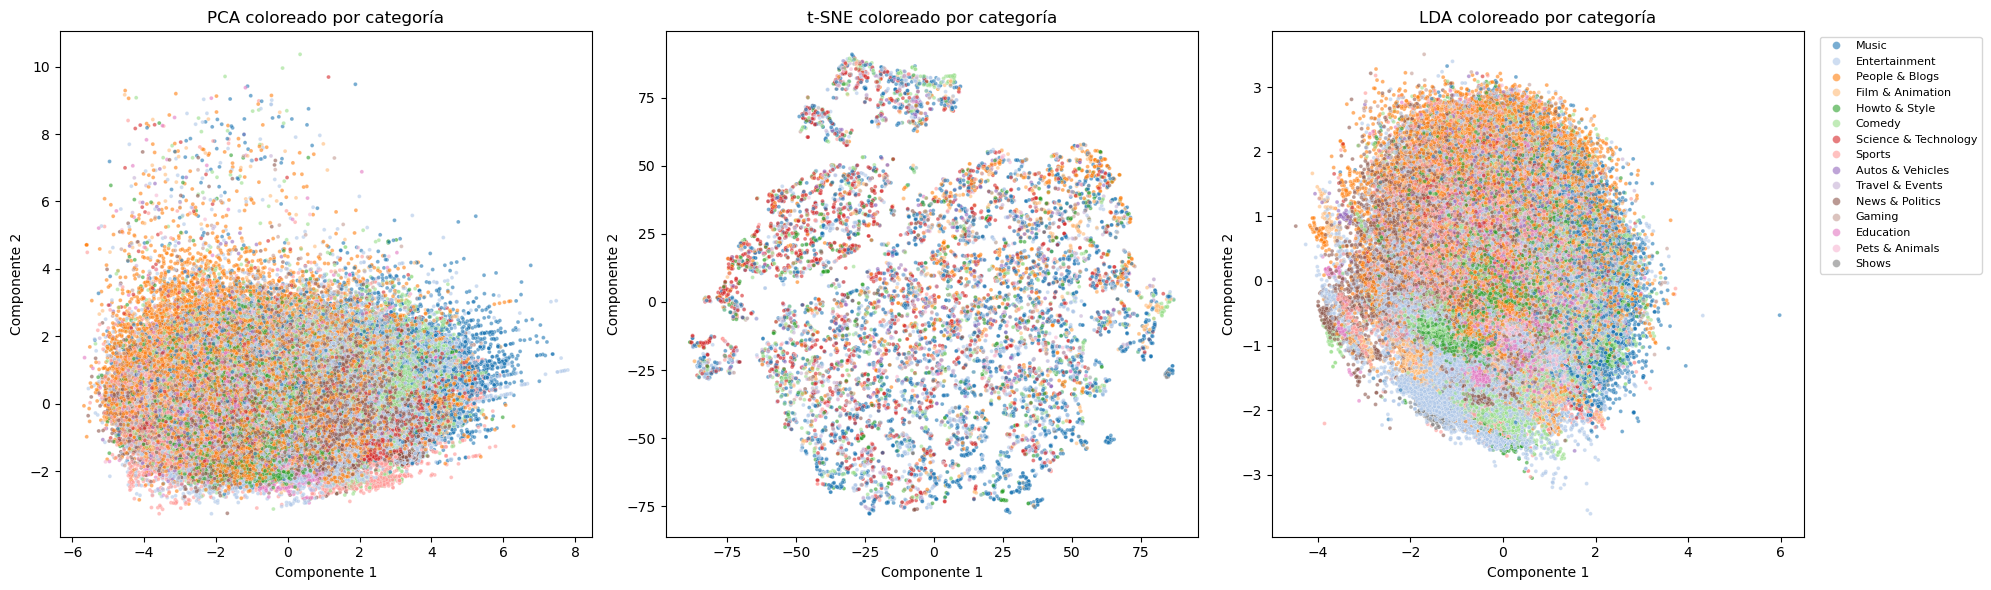

In [867]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

reducciones = {"PCA": X_pca, "t-SNE": X_tsne, "LDA": X_lda}
categorias = {"PCA": y_cluster.values, "t-SNE": y_cluster.values[muestra_tsne], "LDA": y_cluster.values}#t-SNE solo tiene los 10.000 vídeos de su muestra

nombres = list(reducciones.keys())

for i in range(len(nombres)):
    nombre = nombres[i]
    X_red = reducciones[nombre]
    ax = axes[i]

    sns.scatterplot(
        x=X_red[:, 0],
        y=X_red[:, 1],
        hue=categorias[nombre],
        palette="tab20",
        s=8,
        alpha=0.6,
        ax=ax
    )

    if nombre != "LDA":
        ax.get_legend().remove()#para que solo aparezca leyenda a la derecha del todo

    ax.set_title(nombre + " coloreado por categoría")
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")

axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, markerscale=2) #ajustamos la leyenda

plt.tight_layout()
plt.show()

In [868]:
from sklearn.manifold import trustworthiness
from scipy.spatial.distance import pdist

X_muestra = X_cluster[muestra_tsne]#con todos los vídeos no es viable: trustworthiness calcula la distancia entre todas las parejas de vídeos (207.000 x 207.000, unos 340 GB) y pdist guarda una por pareja (21.500 millones, unos 170 GB), y el ordenador tiene 16 GB. Usamos los mismos 10.000 vídeos de t-SNE en las otras dos reducciones
reducciones_muestra = {"PCA": X_pca[muestra_tsne], "t-SNE": X_tsne, "LDA": X_lda[muestra_tsne]}

comparacion = []
for nombre, X_red in reducciones_muestra.items():
    vecinos = trustworthiness(X_muestra, X_red, n_neighbors=5)
    distancias = np.corrcoef(pdist(X_muestra), pdist(X_red))[0, 1]#pdist: distancia entre cada pareja de vídeos. Con los 10.000 vídeos son 50 millones de parejas (unos 400 MB)
    comparacion.append({"Reducción": nombre, "Vecinos (trustworthiness)": vecinos, "Distancias (correlación)": distancias})

pd.DataFrame(comparacion)

,Reducción,Vecinos (trustworthiness),Distancias (correlación)
0,PCA,0.849321,0.867762
1,t-SNE,0.997747,0.549903
2,LDA,0.746265,0.523942


### ¿Con qué reducción nos quedamos?

- **t-SNE** es la que mejor mantiene juntos a los vídeos parecidos (0,998), pero la que peor respeta las distancias junto a LDA (0,55). Es decir: acierta en quién está con quién, pero las separaciones entre zonas del dibujo no son reales. Sirve para dibujar, no para agrupar por cercanía.
- **LDA** es la peor en las dos (0,75 y 0,52) y, además, usa la categoría para construirse, por lo que agrupar sobre ella sería darle la respuesta.
- **PCA** mantiene bien a los vecinos (0,85) y es, con diferencia, la que mejor respeta las distancias (0,87). **Nos quedamos con PCA.**

### K-Means

K-Means reparte los vídeos en k grupos: coloca k centros, asigna cada vídeo al centro más cercano y va moviendo los centros hasta que dejan de cambiar. Hay que decirle de antemano cuántos grupos formar (n_clusters). Usamos el valor por defecto (8); si es el modelo elegido, buscaremos el mejor número de grupos en la optimización.

In [869]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [870]:
kmeans = KMeans(random_state=42)#valores por defecto (n_clusters=8)
etiquetas_kmeans = kmeans.fit_predict(X_pca)

### DBSCAN

DBSCAN agrupa los vídeos que están en zonas con muchos vídeos juntos, y los que quedan aislados los marca como ruido (etiqueta -1). No hay que decirle cuántos grupos formar, pero sí dos parámetros:

- **min_samples:** cuántos vídeos tiene que haber alrededor de un punto para considerar que está en una zona densa. Dejamos el valor por defecto (5).
- **eps:** el radio en el que se buscan esos vecinos. Con el valor por defecto (0,5) no es viable: dentro de ese radio cada vídeo tiene de media unos 6.600 vecinos, más de 1.300 millones en total, que no caben en la memoria del ordenador. Por eso lo elegimos con el método habitual: calculamos, para cada vídeo, la distancia a su vecino número 5 (el valor de min_samples), las ordenamos de menor a mayor y las dibujamos. El punto donde la curva se dispara (el "codo") es un buen valor de eps: por debajo están los vídeos de zonas densas y por encima los aislados.

In [871]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

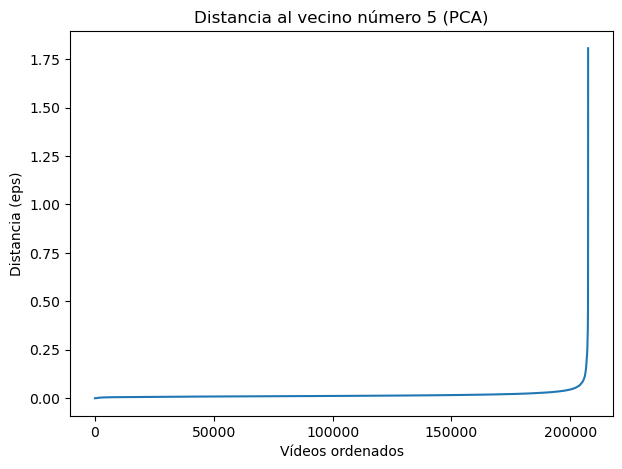

In [872]:
min_samples = 5#valor por defecto de DBSCAN

vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distancias, _ = vecinos.kneighbors(X_pca)
distancias_k = np.sort(distancias[:, -1])#distancia de cada vídeo a su vecino número 5, ordenadas

plt.figure(figsize=(7, 5))
plt.plot(distancias_k)
plt.title("Distancia al vecino número 5 (PCA)")
plt.xlabel("Vídeos ordenados")
plt.ylabel("Distancia (eps)")
plt.show()

La curva se mantiene casi plana para la mayoría de los vídeos y empieza a subir en torno a 0,05, hasta dispararse en los últimos vídeos (los más aislados). Por eso elegimos **eps = 0,05**.

In [873]:
eps_elegido = 0.05#lo fijamos al ver el codo del gráfico. Con el valor por defecto (0,5) cada vídeo tiene de media unos 6.600 vecinos (más de 1.300 millones en total) y no cabe en memoria

dbscan = DBSCAN(eps=eps_elegido)#min_samples por defecto (5)
etiquetas_dbscan = dbscan.fit_predict(X_pca)

### Gaussian Mixture Models (GMM)

GMM supone que los vídeos vienen de varios grupos con forma de campana (distribuciones normales) y calcula la probabilidad de que cada vídeo pertenezca a cada grupo; al final asignamos cada vídeo al grupo más probable. Igual que K-Means, hay que decirle cuántos grupos formar (n_components). Dejamos el valor por defecto, que es 1, por lo que todos los vídeos caerán en el mismo grupo; si fuera el modelo elegido, buscaríamos el número de grupos en la optimización.

In [874]:
from sklearn.mixture import GaussianMixture

In [875]:
gmm = GaussianMixture(random_state=42)#valores por defecto (n_components=1)
etiquetas_gmm = gmm.fit_predict(X_pca)

### HDBSCAN

HDBSCAN funciona como DBSCAN (agrupa zonas densas y marca como ruido los vídeos aislados), pero no necesita eps: prueba él mismo distintos radios y se queda con los grupos más estables. Solo hay que indicarle **min_cluster_size**, el tamaño mínimo que tiene que tener un grupo para considerarlo como tal. Dejamos el valor por defecto (5 vídeos). Es el más lento de los cinco modelos (unos 8 minutos), pero es viable.

In [876]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN()#valores por defecto (min_cluster_size=5). Tarda unos 8 minutos
etiquetas_hdbscan = hdbscan.fit_predict(X_pca)

### Mean-Shift

Mean-Shift busca las zonas donde se concentran más vídeos: mueve cada punto poco a poco hacia la zona más densa de su alrededor, y los vídeos que acaban en la misma zona forman un grupo. Igual que DBSCAN y HDBSCAN, no hay que decirle cuántos grupos formar, pero sí el **bandwidth**, el radio en el que mira alrededor de cada punto. Con los valores por defecto no es viable, así que cambiamos dos cosas:

- **bandwidth:** por defecto lo calcula con estimate_bandwidth usando todos los vídeos, comparando cada uno con el 30 % de vídeos más cercanos. Con todos lo dejamos más de 50 minutos y no llegó a terminar, así que lo estimamos con 10.000 vídeos al azar, que tarda unos segundos.
- **bin_seeding:** por defecto empieza a buscar desde cada uno de los 207.000 vídeos. Lo probamos con 1.000, 2.000 y 4.000 vídeos al azar: tardó 4,5, 12,5 y 32 segundos, es decir, el tiempo se multiplica por unas 2,6 veces cada vez que doblamos los vídeos, así que con todos tardaría unas 2 horas. Con bin_seeding=True empieza desde una rejilla de puntos en lugar de desde cada vídeo: con 4.000 vídeos tardó 1,2 segundos en lugar de 32.

Como con SVM, aquí lo ajustamos para que se ejecute en un tiempo razonable: en las pruebas previas, además de tardar mucho, Mean-Shift metía todos los vídeos en un único grupo, por lo que no iba a ser el modelo que eligiéramos.

In [877]:
from sklearn.cluster import MeanShift, estimate_bandwidth

ancho = estimate_bandwidth(X_pca, n_samples=10000, random_state=42)#con todos los vídeos (valor por defecto) lo dejamos más de 50 minutos y no terminó, así que lo estimamos con 10.000 al azar

print("Bandwidth:", ancho)

meanshift = MeanShift(bandwidth=ancho, bin_seeding=True)#bin_seeding: empieza desde una rejilla de puntos en lugar de desde cada vídeo. Por defecto (False) tardaría unas 2 horas
#Tras varias pruebas, sabiendo que no iba a ser el modelo elegido (mete todos los vídeos en un único grupo), lo ajustamos para que se ejecute rápido
etiquetas_meanshift = meanshift.fit_predict(X_pca)

Bandwidth: 1.8685678687778673


### Comparativa de los modelos de clusterización

Comparamos los cinco modelos con estas métricas:

- **Nº de clusters** y **% de ruido:** cuántos grupos forma cada modelo y qué parte de los vídeos deja sin grupo (solo DBSCAN y HDBSCAN marcan ruido).
- **Silhouette:** si los grupos están bien separados entre sí. Va de -1 a 1, cuanto mayor mejor.
- **ARI:** cuánto se parecen los grupos a las categorías reales de los vídeos, que es lo que pide el enunciado. Vale 0 si no se parecen nada y 1 si coinciden por completo.

La silhouette se calcula sobre PCA. Como compara cada vídeo con todos los demás, la calculamos sobre 10.000 vídeos al azar (los grupos sí se forman con todos). Lo comprobamos con K-Means de 4 grupos: con todos los vídeos tardó unos 8 minutos y dio 0,349, y con 10.000 tardó menos de 2 segundos y dio 0,347. Además, repitiéndola con 5 muestras distintas de 10.000 vídeos, para cada número de grupos los resultados varían menos de 0,01. Con todos los vídeos la tabla tardaría unos 40 minutos y la optimización horas, ya que en ella la calculamos decenas de veces. En DBSCAN y HDBSCAN la calculamos sin los vídeos marcados como ruido, ya que no pertenecen a ningún grupo.

In [878]:
from sklearn.metrics import adjusted_rand_score

In [879]:
def metricas_cluster(nombre, etiquetas):
    sin_ruido = etiquetas != -1#DBSCAN y HDBSCAN marcan el ruido con -1
    n_clusters = len(set(etiquetas[sin_ruido]))

    if n_clusters >= 2:#la silhouette necesita al menos 2 grupos
        silueta = silhouette_score(X_pca[sin_ruido], etiquetas[sin_ruido], sample_size=10000, random_state=42)#sobre 10.000 vídeos al azar: con todos tarda unos 8 minutos por modelo y sale prácticamente igual (lo explicamos arriba)
    else:
        silueta = np.nan

    return {
        "Modelo": nombre,
        "Nº clusters": n_clusters,
        "% ruido": 100 * (etiquetas == -1).mean(),
        "Silhouette": silueta,
        "ARI": adjusted_rand_score(y_cluster, etiquetas)
    }

In [880]:
df_clusters = pd.DataFrame([
    metricas_cluster("K-Means", etiquetas_kmeans),
    metricas_cluster("DBSCAN", etiquetas_dbscan),
    metricas_cluster("GMM", etiquetas_gmm),
    metricas_cluster("HDBSCAN", etiquetas_hdbscan),
    metricas_cluster("Mean-Shift", etiquetas_meanshift)
])

df_clusters = df_clusters.sort_values(by="Silhouette", ascending=False)

tabla_clusters = df_clusters.style

tabla_clusters = tabla_clusters.highlight_max(subset=["Silhouette", "ARI"], props="font-weight: bold; font-size: 16px;")#cuanto mayor mejor

tabla_clusters.hide()#ocultamos el indice

Modelo,Nº clusters,% ruido,Silhouette,ARI
K-Means,8,0.000000,0.324963,0.021110
HDBSCAN,11063,38.214003,0.291947,-0.002071
DBSCAN,292,2.105141,-0.274350,0.003634
GMM,1,0.000000,nan,0.000000
Mean-Shift,1,0.000000,nan,0.000000


Dibujamos los grupos de cada modelo sobre el mismo gráfico de PCA de antes, para compararlos con el gráfico coloreado por categoría. En DBSCAN y HDBSCAN el grupo -1 son los vídeos marcados como ruido.

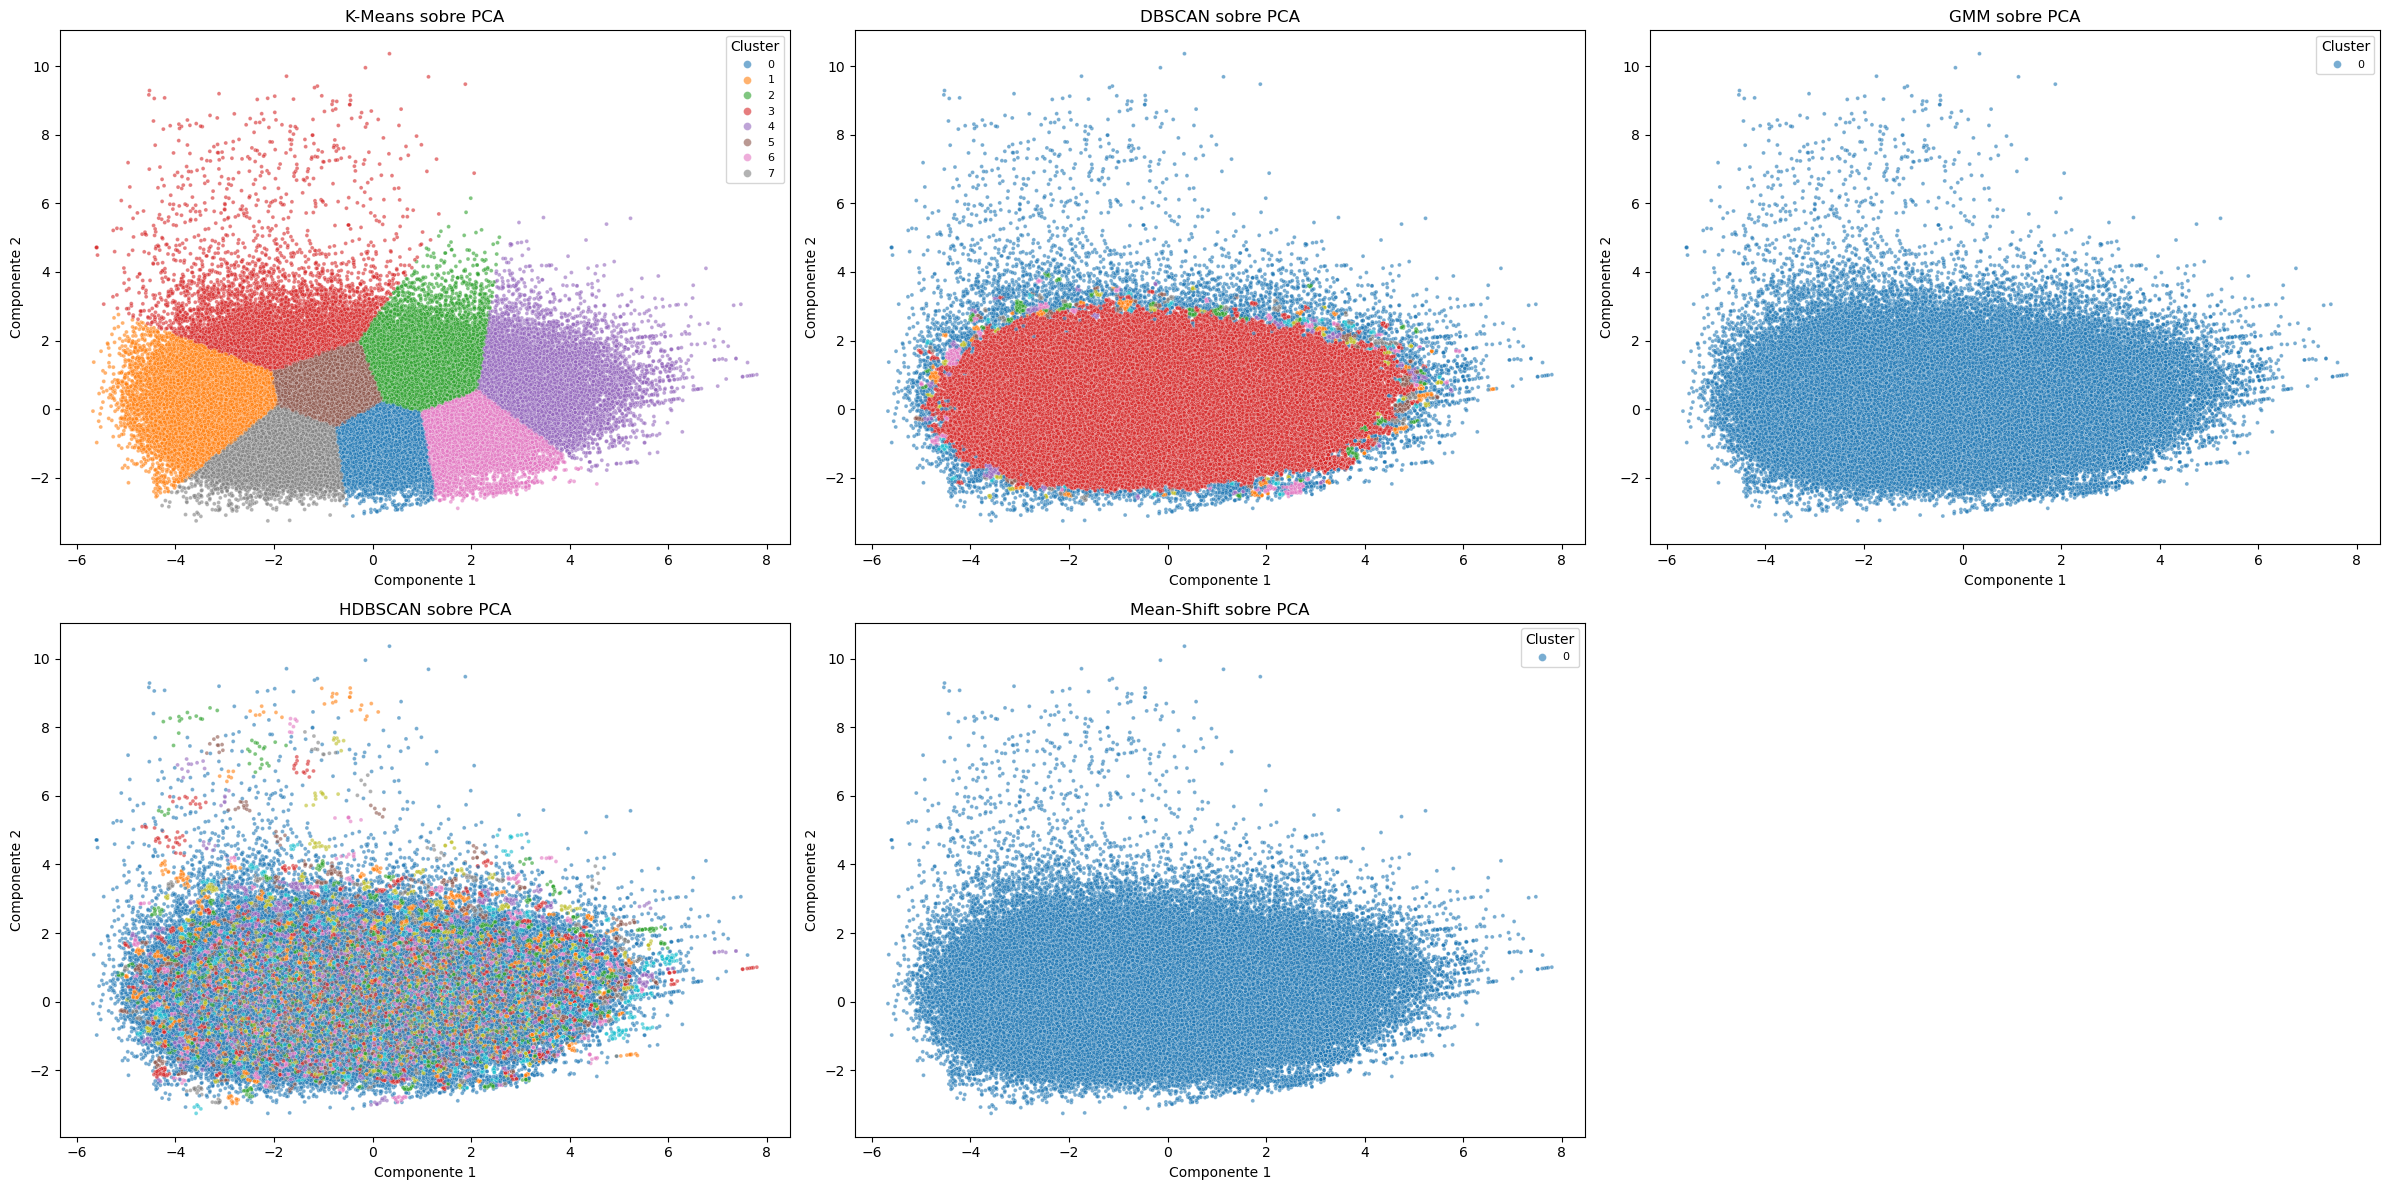

In [881]:
modelos_cluster = {"K-Means": etiquetas_kmeans, "DBSCAN": etiquetas_dbscan, "GMM": etiquetas_gmm, "HDBSCAN": etiquetas_hdbscan, "Mean-Shift": etiquetas_meanshift}

fig, axes = plt.subplots(2, 3, figsize=(24, 12))

for ax, (nombre, etiquetas) in zip(axes.flatten(), modelos_cluster.items()):
    con_leyenda = len(set(etiquetas)) <= 20#HDBSCAN forma miles de grupos: con tantos la leyenda no se puede leer
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=etiquetas, palette="tab10", s=8, alpha=0.6, legend=con_leyenda, ax=ax)
    ax.set_title(f"{nombre} sobre PCA")
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")
    if con_leyenda:
        ax.legend(title="Cluster", fontsize=8, markerscale=2)

axes.flatten()[-1].axis("off")#son 5 modelos: el sexto hueco queda vacío

plt.tight_layout()
plt.show()

### Conclusiones: ¿con qué modelo nos quedamos?

Nos quedamos con **K-Means**, que es el que tiene la silhouette más alta (0,33) y reparte todos los vídeos en grupos.

- **K-Means**, con los 8 grupos que forma por defecto, parte la nube de vídeos en 8 trozos con una silhouette de 0,33.
- **HDBSCAN** tiene una silhouette parecida (0,29), pero forma más de 11.000 grupos minúsculos (con el mínimo de 5 vídeos por grupo que tiene por defecto) y deja el 38 % de los vídeos como ruido, así que no sirve para describir los vídeos.
- **DBSCAN** mete el 96 % de los vídeos en un único grupo gigante y reparte el resto en casi 300 grupos de unos pocos vídeos. Su silhouette es negativa (-0,27).
- **GMM**, con el valor por defecto de 1 grupo, mete todos los vídeos en el mismo grupo, así que no se puede calcular su silhouette.
- **Mean-Shift** también mete todos los vídeos en un único grupo.

A continuación optimizamos K-Means.

### Optimización de K-Means

Igual que con los modelos anteriores, buscamos la mejor combinación de hiperparámetros. Como son pocas combinaciones, podemos probarlas todas con GridSearchCV:

- **n_clusters:** de 2 a 10 grupos. Es el parámetro principal: con el valor por defecto (8) no sabemos si es el número de grupos adecuado.
- **init:** cómo se colocan los centros al empezar: "k-means++" (el valor por defecto, que los coloca separados entre sí) o "random" (al azar).
- **n_init:** cuántas veces se repite el algoritmo empezando desde centros distintos, quedándose con la mejor. Por defecto ("auto") lo hace una sola vez con k-means++ y 10 veces con random. Probamos también 10 veces con k-means++, por si una sola vez se queda en una mala solución.

No probamos algorithm ("lloyd" o "elkan"), ya que solo cambia la forma de hacer los cálculos (la velocidad), no los grupos que salen, ni max_iter, ya que el modelo converge en pocas iteraciones, muy por debajo de las 300 que tiene por defecto (lo mostramos al final de la celda).

Como no hay una respuesta correcta con la que comparar, puntuamos cada combinación con la silhouette, sobre 10.000 vídeos al azar como antes. Usamos cv=2 como en el resto del notebook: K-Means aprende los centros con la mitad de los vídeos y medimos la silhouette en la otra mitad. Ponemos primero los valores por defecto: si dos combinaciones empatan, GridSearchCV se queda con la primera, es decir, con la de los valores por defecto.

In [882]:
from sklearn.model_selection import GridSearchCV, KFold

def silueta(estimador, X, y=None):#GridSearchCV necesita una función que puntúe cada combinación: le damos la silhouette de los grupos que forma
    return silhouette_score(X, estimador.predict(X), sample_size=10000, random_state=42)

param_grid_kmeans = {
    "n_clusters": list(range(2, 11)),
    "init": ["k-means++", "random"],#primero el valor por defecto: si empatan, se queda con él
    "n_init": ["auto", 10]
}

grid_search_kmeans = GridSearchCV(
    estimator=KMeans(random_state=42),
    param_grid=param_grid_kmeans,
    scoring=silueta,
    verbose=1,
    cv=KFold(n_splits=2, shuffle=True, random_state=42)#los vídeos están ordenados (por ejemplo, Canadá es el 19 % de la primera mitad y el 5 % de la segunda), así que los mezclamos antes de partirlos en dos
)

grid_search_kmeans.fit(X_pca)

kmeans_optimo = grid_search_kmeans.best_estimator_

print("Best parameters:", grid_search_kmeans.best_params_)
print("Best CV silhouette:", grid_search_kmeans.best_score_)
print("Iteraciones hasta converger:", kmeans_optimo.n_iter_)

Fitting 2 folds for each of 36 candidates, totalling 72 fits
Best parameters: {'init': 'k-means++', 'n_clusters': 2, 'n_init': 'auto'}
Best CV silhouette: 0.41144587226804036
Iteraciones hasta converger: 10


Vemos la silhouette de las 10 mejores combinaciones:

In [883]:
resultados_kmeans = pd.DataFrame(grid_search_kmeans.cv_results_)[["param_n_clusters", "param_init", "param_n_init", "mean_test_score", "rank_test_score"]]

resultados_kmeans.sort_values(by="rank_test_score").head(10)

,param_n_clusters,param_init,param_n_init,mean_test_score,rank_test_score
0,2,k-means++,auto,0.411446,1
1,2,k-means++,10,0.411446,1
18,2,random,auto,0.411375,3
19,2,random,10,0.411375,3
5,4,k-means++,10,0.343826,5
4,4,k-means++,auto,0.343779,6
22,4,random,auto,0.343044,7
23,4,random,10,0.343044,7
6,5,k-means++,auto,0.330669,9
3,3,k-means++,10,0.330567,10


La mejor combinación es **2 grupos con el resto de parámetros por defecto** (init="k-means++" y n_init="auto"), con una silhouette en validación de 0,41, frente a 0,34 de la siguiente opción, 4 grupos.

- **n_init:** repetir el algoritmo 10 veces da exactamente la misma silhouette que hacerlo una sola vez (las dos combinaciones empatan en el primer puesto), así que no aporta nada y nos quedamos con el valor por defecto.
- **init:** colocar los centros al azar (random) sale prácticamente igual, aunque algo peor (0,41138 frente a 0,41145 con k-means++), así que también nos quedamos con el valor por defecto.
- El modelo converge en 10 iteraciones, muy por debajo de las 300 de max_iter.

Añadimos el K-Means optimizado a la tabla comparativa para ver la mejora respecto al resto de modelos.

In [884]:
etiquetas_kmeans_optimo = kmeans_optimo.predict(X_pca)

df_clusters = pd.concat([df_clusters, pd.DataFrame([metricas_cluster("K-Means optimizado", etiquetas_kmeans_optimo)])], ignore_index=True)#ignore_index: sin él se repetiría el índice 0 y el estilo de la tabla da error

df_clusters = df_clusters.sort_values(by="Silhouette", ascending=False)

tabla_clusters = df_clusters.style

tabla_clusters = tabla_clusters.highlight_max(subset=["Silhouette", "ARI"], props="font-weight: bold; font-size: 16px;")#cuanto mayor mejor

tabla_clusters.hide()#ocultamos el indice

Modelo,Nº clusters,% ruido,Silhouette,ARI
K-Means optimizado,2,0.000000,0.412293,0.014299
K-Means,8,0.000000,0.324963,0.021110
HDBSCAN,11063,38.214003,0.291947,-0.002071
DBSCAN,292,2.105141,-0.274350,0.003634
GMM,1,0.000000,nan,0.000000
Mean-Shift,1,0.000000,nan,0.000000


Para ver qué tipo de vídeos hay en cada grupo, dibujamos los grupos sobre PCA y comparamos la mediana de cada variable en cada grupo (usamos la mediana porque views, likes, dislikes y comment_count tienen muchos outliers).

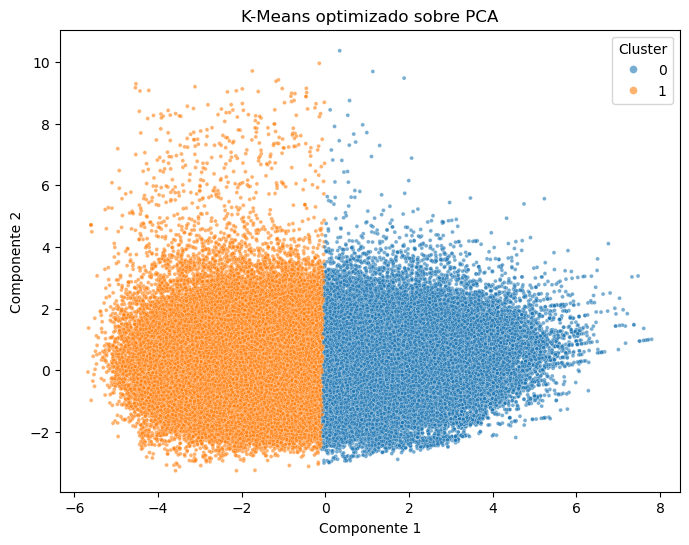

,views,likes,dislikes,comment_count,dias_desde_publicacion,n_tags,longitud_titulo,n_videos_canal
0,296748.0,6932.0,341.0,957.0,1.0,19.0,51.0,32.0
1,24533.0,357.0,21.0,59.0,1.0,10.0,52.0,10.0


In [885]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=etiquetas_kmeans_optimo, palette="tab10", s=8, alpha=0.6)
plt.title("K-Means optimizado sobre PCA")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Cluster", markerscale=2)
plt.show()

df.groupby(etiquetas_kmeans_optimo)[variables_cluster].median()

### Conclusiones de la clusterización

El K-Means optimizado mejora al K-Means por defecto: la silhouette pasa de 0,32 a 0,41 al formar 2 grupos en lugar de 8, y es el mejor de todos los modelos. Es el modelo que industrializamos.

**¿Qué hay en cada grupo?** Los dos grupos separan los vídeos por su popularidad:

- **Grupo 0:** los vídeos más populares (mediana de unas 297.000 views, 6.900 likes y 960 comentarios), con más tags (19) y de canales que salen a menudo en tendencias (32 vídeos del mismo canal).
- **Grupo 1:** los menos populares (unas 25.000 views, 360 likes y 59 comentarios), con menos tags (10) y de canales menos habituales (10 vídeos).

La longitud del título y los días hasta ser tendencia son prácticamente iguales en los dos grupos, así que no influyen en la separación. Hay que tener en cuenta que no son grupos naturales: como vimos en PCA, los vídeos forman una sola nube, y K-Means simplemente la parte en dos.

**¿Se parecen los clusters a las categorías?** No. El ARI de todos los modelos está muy cerca de 0 (como mucho 0,02), es decir, los grupos no tienen relación con las categorías de los vídeos. Es lo que ya anticipaban las reducciones: con estas variables, que miden sobre todo la popularidad y la interacción, las categorías salen mezcladas, incluso con LDA, que las conoce.

## 7. Recomendador

Para el recomendador usamos un **enfoque basado en contenido**: dado un vídeo, buscamos los vídeos cuyo texto (título, tags, canal y categoría) se parece más al suyo.

### ¿Qué variables usamos y por qué?

- **title y tags:** son las que dicen de qué trata el vídeo.
- **channel_title:** los vídeos de un mismo canal suelen tratar temas parecidos.
- **category:** ayuda a que las recomendaciones sean del mismo tipo de vídeo.
- **No usamos views, likes, dislikes ni comment_count:** miden la popularidad, no de qué trata el vídeo. En la clusterización vimos que, con estas variables, los grupos no tenían ninguna relación con las categorías (ARI cerca de 0).
- **No usamos pais:** indica dónde fue tendencia el vídeo, no su contenido.
- **No usamos description:** la eliminamos en el preprocesamiento.

In [886]:
from sklearn.feature_extraction.text import TfidfVectorizer

Preparamos los datos para el recomendador. Cargamos de nuevo el dataset limpio, ya que en los apartados anteriores modificamos df. Un mismo vídeo puede estar repetido en varios países, así que nos quedamos con un único registro por vídeo (el de más views) para que no nos recomiende el mismo vídeo varias veces. Después juntamos en la columna contenido el título, los tags, el canal y la categoría, que es el texto con el que compararemos los vídeos.

In [887]:
df_reco = pd.read_pickle("dataframe_final_limpio.pkl")

df_reco = df_reco.sort_values(by="views", ascending=False)
df_reco = df_reco.drop_duplicates(subset=["title", "channel_title"], keep="first")#en el preprocesamiento dejamos un registro por vídeo y país; aquí quitamos el país para no recomendar el mismo vídeo varias veces
df_reco = df_reco.reset_index(drop=True)#reiniciamos el índice para que cada fila coincida con su posición en la matriz TF-IDF

def unir_tags(tags):
    if tags == ["[none]"]:#por si no hubiera ningun tag
        return ""
    return " ".join(tags)

df_reco["contenido"] = df_reco["title"] + " " + df_reco["tags"].apply(unir_tags) + " " + df_reco["channel_title"] + " " + df_reco["category"]

df_reco.shape

(184631, 14)

### Vectorización con TF-IDF

Convertimos la columna contenido en una matriz TF-IDF, en la que cada fila es un vídeo y cada columna una palabra. Usamos solo contenido, que ya junta las variables que describen el tema del vídeo (título, tags, canal y categoría).

- **stop_words="english":** quitamos las palabras vacías en inglés ("the", "of", "and"...), que no dicen nada del tema. Solo existe la lista en inglés, pero en el resto de idiomas el propio TF-IDF da poco peso a las palabras que salen en muchos vídeos.
- **min_df=2:** ignoramos las palabras que solo aparecen en un vídeo, ya que no sirven para relacionarlo con ningún otro.
- **max_features=50000:** nos quedamos con las 50.000 palabras más frecuentes para que la matriz no se dispare en memoria.

In [888]:
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_features=50000)

X_tfidf = tfidf.fit_transform(df_reco["contenido"])

X_tfidf.shape

(184631, 50000)

### KNeighborsClassifier

Entrenamos el modelo con la matriz TF-IDF y la categoría de cada vídeo como etiqueta. Para recomendar solo usaremos su método kneighbors, que no depende de la etiqueta; la categoría la necesita el fit y nos servirá después para evaluar las recomendaciones.

- **metric="cosine":** compara los textos por su contenido sin que influya lo largos que son.
- **algorithm="brute":** es el único algoritmo que admite la métrica del coseno con matrices dispersas como la de TF-IDF.
- **n_neighbors=11:** el vecino más cercano de un vídeo es el propio vídeo, así que pedimos 11 para quedarnos con 10 recomendaciones.

In [889]:
from sklearn.neighbors import KNeighborsClassifier

knn_reco = KNeighborsClassifier(n_neighbors=11, metric="cosine", algorithm="brute")
knn_reco.fit(X_tfidf, df_reco["category"])

KNeighborsClassifier(algorithm='brute', metric='cosine', n_neighbors=11)

### Función recomendar

Creamos una función que recibe un texto, busca el vídeo cuyo título lo contiene y devuelve los n vídeos más parecidos. Si hay varios vídeos con ese texto en el título nos quedamos con el más visto. Mostramos título, canal, categoría, país y views para poder comprobar si las recomendaciones tienen sentido, y la similitud (1 - distancia del coseno), que va de 0 (nada parecidos) a 1 (iguales).

In [890]:
def recomendar(texto, n=10):
    coincidencias = df_reco[df_reco["title"].str.contains(texto, case=False, regex=False)]
    if coincidencias.empty:
        print("No hemos encontrado ningún vídeo con ese título")
        return None

    i = coincidencias.index[0]#df_reco está ordenado por views, así que el primero es el más visto
    print("Vídeo elegido:", df_reco.loc[i, "title"], "|", df_reco.loc[i, "channel_title"], "|", df_reco.loc[i, "category"])

    distancias, indices = knn_reco.kneighbors(X_tfidf[i], n_neighbors=n + 1)

    recomendaciones = df_reco.loc[indices[0], ["title", "channel_title", "category", "pais", "views"]].copy()
    recomendaciones["similitud"] = 1 - distancias[0]
    recomendaciones = recomendaciones.drop(index=i, errors="ignore").head(n)#quitamos el propio vídeo

    return recomendaciones

### Pruebas del recomendador

Probamos el recomendador con el vídeo más visto de tres categorías distintas (Music, Sports y Gaming) para ver si las recomendaciones tienen relación con el vídeo elegido.

In [891]:
recomendar(df_reco[df_reco["category"] == "Music"]["title"].iloc[0])

Vídeo elegido: Nicky Jam x J. Balvin - X (EQUIS) | Video Oficial | Prod. Afro Bros & Jeon | NickyJamTV | Music


,title,channel_title,category,pais,views,similitud
119,Nicky Jam x J. Balvin - X (EQUIS) | Video Oficial,NickyJamTV,Music,Francia,30686233,0.970242
53800,Nicky Jam x J. Balvin - X (EQUIS) by Nailas,Nil Ojeda,Entertainment,Mexico,188912,0.869775
11455,Nicky Jam x J. Balvin - X (EQUIS) | Video PARO...,Werevertumorro,Entertainment,Mexico,960233,0.483118
15473,Lo mejor del X (equis) challenge #XChallenge -...,NickyJamTV,Music,Mexico,743730,0.393668
115,Brytiago X Darell - Asesina 🗡,Brytiago Cartel Records,Music,Francia,31791115,0.388162
100380,Todo Comienza En La Disco - Wisin Ft. Yandel Y...,wisin Victory,People & Blogs,Mexico,60944,0.351503
1027,"Wisin, Yandel, Daddy Yankee - Todo Comienza en...",wisinofficalVEVO,Music,Mexico,5877577,0.335377
10,"Luis Fonsi, Demi Lovato - Échame La Culpa",LuisFonsiVEVO,Music,Gran Bretaña,143408235,0.321923
135661,REGGAETON MIX 2018 LOS EXITOS MAS PEGADOS Ozun...,DjMenLatinoNYCHD,News & Politics,Mexico,23669,0.321560
2023,Piso 21 - La Vida Sin Ti (Video Oficial),piso21music,Music,Mexico,3494203,0.306108


In [892]:
recomendar(df_reco[df_reco["category"] == "Sports"]["title"].iloc[0])

Vídeo elegido: Real Life Trick Shots 2 | Dude Perfect | Dude Perfect | Sports


,title,channel_title,category,pais,views,similitud
260,Football vs Soccer Trick Shots | Dude Perfect,Dude Perfect,Sports,USA,18094162,0.939341
183,Boomerang Trick Shots | Dude Perfect,Dude Perfect,Sports,USA,22233274,0.927157
4197,Overtime | Episode 1 | Dude Perfect,Dude Perfect,Sports,Canadá,2055743,0.921215
290,Giant Darts Battle | Dude Perfect,Dude Perfect,Sports,USA,16371326,0.918103
618,Best of 2017 | Dude Perfect,Dude Perfect,Sports,USA,8930421,0.915271
1075,Wheel Unfortunate | Dude Perfect,Dude Perfect,Sports,Canadá,5657263,0.906891
354,All Sports Golf Battle 2 | Dude Perfect,Dude Perfect,Sports,USA,14107720,0.901899
229,World's Longest LEGO Walk | Dude Perfect,Dude Perfect,Sports,USA,19412787,0.898151
264,Fortnite with Ninja | Dude Perfect,Dude Perfect,Sports,USA,18040000,0.897794
269,Deep Sea Fishing Battle | Dude Perfect,Dude Perfect,Sports,USA,17345023,0.895152


In [893]:
recomendar(df_reco[df_reco["category"] == "Gaming"]["title"].iloc[0])

Vídeo elegido: Yodeling Walmart Kid EDM Remix (OFFICIAL AUDIO) + DOWNLOAD LINK | GalacticFusion | Gaming


,title,channel_title,category,pais,views,similitud
36271,YODELING IN WALMART - SINGING IN PUBLIC!!! (Yo...,QPark,Entertainment,Mexico,312157,0.869858
24205,Little Boy Yodeling in Walmart Remix,h6deed,People & Blogs,Canadá,481973,0.811342
36579,Little Boy Yodeling in Walmart REMIX,h6deed,People & Blogs,Alemania,309169,0.811342
39780,Yodeling Walmart Boy Meme Compilation Pt. 2,"2,640,195 views",Entertainment,Canadá,280663,0.784774
22043,Kid Singing in Walmart (Lowercase EDM Remix),PRISM,People & Blogs,Canadá,528782,0.772720
1795,Walmart yodeling kid,Sonell Official,People & Blogs,Alemania,3815944,0.680670
78206,¿Quién es YODELING KID ? - Draw My Life en Esp...,Draw My Life en Español,Entertainment,Mexico,102231,0.655860
14534,Lil Tay Likes The Walmart Yodeling Kid,Five_ly,Comedy,Canadá,787915,0.647274
45034,The Untold Truth Of The Walmart Kid Yodeler,Nicki Swift,Entertainment,Canadá,240419,0.628584
8372,Walmart Kid Singing | Full Version (ORIGINAL V...,TheBestVidz,Entertainment,Canadá,1231149,0.576056


### Conclusiones de las pruebas

- **Music (Nicky Jam x J. Balvin - X):** las primeras recomendaciones son el mismo vídeo con un título algo distinto (similitud 0,97), versiones y challenges de la canción, y después otras canciones de reggaeton y música latina (Wisin, Luis Fonsi, Piso 21...). Las recomendaciones tienen sentido, aunque se cuelan algunos vídeos de otras categorías porque hablan de la misma canción.
- **Sports (Dude Perfect):** las 10 recomendaciones son del mismo canal y con similitudes muy altas (alrededor de 0,9). Son muy parecidas, pero poco variadas: el nombre del canal aparece en el título, los tags y channel_title, así que tiene mucho peso.
- **Gaming (Yodeling Walmart Kid):** todas las recomendaciones tratan del mismo tema (el niño que canta en Walmart), pero ninguna es de Gaming. En realidad el vídeo elegido no es de videojuegos aunque el creador lo puso en esa categoría, así que el recomendador sigue el tema del vídeo y no la categoría.

En los tres casos el recomendador encuentra vídeos del mismo tema. Como punto débil, tiende a recomendar el mismo vídeo resubido o muchos vídeos de un mismo canal.

### Evaluación del recomendador

Un recomendador no tiene una respuesta correcta con la que comparar, así que lo evaluamos de forma aproximada con la categoría: si las recomendaciones son buenas, la mayoría deberían ser de la misma categoría que el vídeo consultado.

Tomamos una muestra de 1.000 vídeos al azar (con todos tardaría unos 14 minutos y el resultado apenas cambia, lo explicamos en la celda) y calculamos el % de sus recomendaciones que son de la misma categoría. Para saber si es un buen resultado lo comparamos con lo que saldría recomendando vídeos al azar, que depende de cuántos vídeos tiene cada categoría.

In [894]:
muestra = df_reco.sample(1000, random_state=42).index#con los 184.000 vídeos tarda unos 14 minutos. Con 1.000 tarda unos segundos y el resultado apenas cambia: con otras dos muestras de 1.000 sale entre el 72 % y el 73 %, y con 10.000 un 72,3 %

distancias_muestra, indices_muestra = knn_reco.kneighbors(X_tfidf[muestra])

misma_categoria = []
for video, vecinos in zip(muestra, indices_muestra):
    vecinos = [v for v in vecinos if v != video][:10]#quitamos el propio vídeo
    misma_categoria.append((df_reco.loc[vecinos, "category"] == df_reco.loc[video, "category"]).mean())

proporciones = df_reco["category"].value_counts(normalize=True)
azar = (proporciones ** 2).sum()#probabilidad de que un vídeo al azar sea de la misma categoría

print(f"Recomendaciones de la misma categoría (KNN): {np.mean(misma_categoria) * 100:.1f} %")
print(f"Recomendaciones de la misma categoría (azar): {azar * 100:.1f} %")

Recomendaciones de la misma categoría (KNN): 72.0 %
Recomendaciones de la misma categoría (azar): 15.2 %


El 72 % de las recomendaciones son de la misma categoría que el vídeo consultado, frente al 15,2 % que obtendríamos recomendando al azar, casi 5 veces más. El recomendador no usa la categoría para buscar los vecinos de forma directa (solo es una palabra más dentro de contenido), por lo que este resultado indica que las recomendaciones son de vídeos con un contenido parecido.

Además, como KNeighborsClassifier es un clasificador, comprobamos con classification_report si los vecinos de un vídeo "votan" su categoría correcta. Para ello separamos en train y test: si usáramos los mismos vídeos, cada vídeo se encontraría a sí mismo como vecino y acertaría siempre.

In [895]:
Xtrain_reco, Xtest_reco, ytrain_reco, ytest_reco = train_test_split(X_tfidf, df_reco["category"], test_size=0.2, random_state=42, stratify=df_reco["category"])

knn_eval = KNeighborsClassifier(n_neighbors=10, metric="cosine", algorithm="brute")
knn_eval.fit(Xtrain_reco, ytrain_reco)

y_pred_reco = knn_eval.predict(Xtest_reco)

print(classification_report(ytest_reco, y_pred_reco))

C:\Users\luci_\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                       precision    recall  f1-score   support

     Autos & Vehicles       0.85      0.91      0.88       688
               Comedy       0.80      0.76      0.78      2174
            Education       0.83      0.68      0.75       828
        Entertainment       0.78      0.85      0.81     10720
     Film & Animation       0.80      0.73      0.76      1881
               Gaming       0.84      0.75      0.79      1132
        Howto & Style       0.81      0.80      0.80      1958
               Movies       1.00      0.50      0.67         2
                Music       0.77      0.69      0.73      2130
      News & Politics       0.82      0.87      0.85      4506
Nonprofits & Activism       0.00      0.00      0.00         3
       People & Blogs       0.77      0.69      0.73      6734
       Pets & Animals       0.84      0.91      0.87       473
 Science & Technology       0.80      0.75      0.77       703
                Shows       0.72      0.70      0.71  

C:\Users\luci_\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\luci_\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


El modelo acierta la categoría del 80 % de los vídeos de test, con un F1 macro de 0,69. Es mucho mejor que lo que conseguimos en la predicción de categoría con las variables numéricas (accuracy de 0,41 y F1 macro de 0,32), lo que confirma que la categoría depende del contenido del vídeo (título, tags y canal) y no de su popularidad.

Las únicas categorías que fallan son Movies, Nonprofits & Activism y Trailers, que tienen solo 1, 2 o 3 vídeos en test. Aparecen aquí porque para el recomendador volvimos a cargar el dataset limpio, y en él no habíamos eliminado estas categorías (las quitamos de df en el EDA). El aviso que sale (UndefinedMetricWarning) se debe a que el modelo no predice nunca alguna de ellas.